## Перенос координат генов fantom l2 с GRCh37 на GRCh38

In [22]:
from pathlib import Path
import os
import pandas as pd
import numpy as np
import pybedtools
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter, defaultdict

In [673]:
ROOT = Path().cwd()
DATA = Path("../data").resolve()
DATA_INITIAL = Path("../data_initial").resolve()
FANTOM = DATA / "fantom_cat"
FANTOM_INITIAL = DATA_INITIAL / "fantom_cat"
ANNO = Path("/export/home/public/agletdinov_shared/annotations")
LIFTOVER = DATA / "liftover"
ENSEMBL = DATA / "ensembl"
ENSEMBL_INITIAL = DATA_INITIAL / "ensembl"
GENCODE = DATA / "gencode"
GENCODE_INITIAL = DATA_INITIAL / "gencode"
ID_HISTORY_CONVERTER_RES = DATA / "id_history_converter_res"
HGNC_INITIAL = DATA_INITIAL / "HGNC"

In [674]:
for directory in DATA_INITIAL, FANTOM_INITIAL, DATA, FANTOM, LIFTOVER, ENSEMBL_INITIAL, ENSEMBL, GENCODE_INITIAL, GENCODE, ID_HISTORY_CONVERTER_RES, HGNC_INITIAL:
    directory.mkdir(exist_ok=True, parents=True)

p.s. 
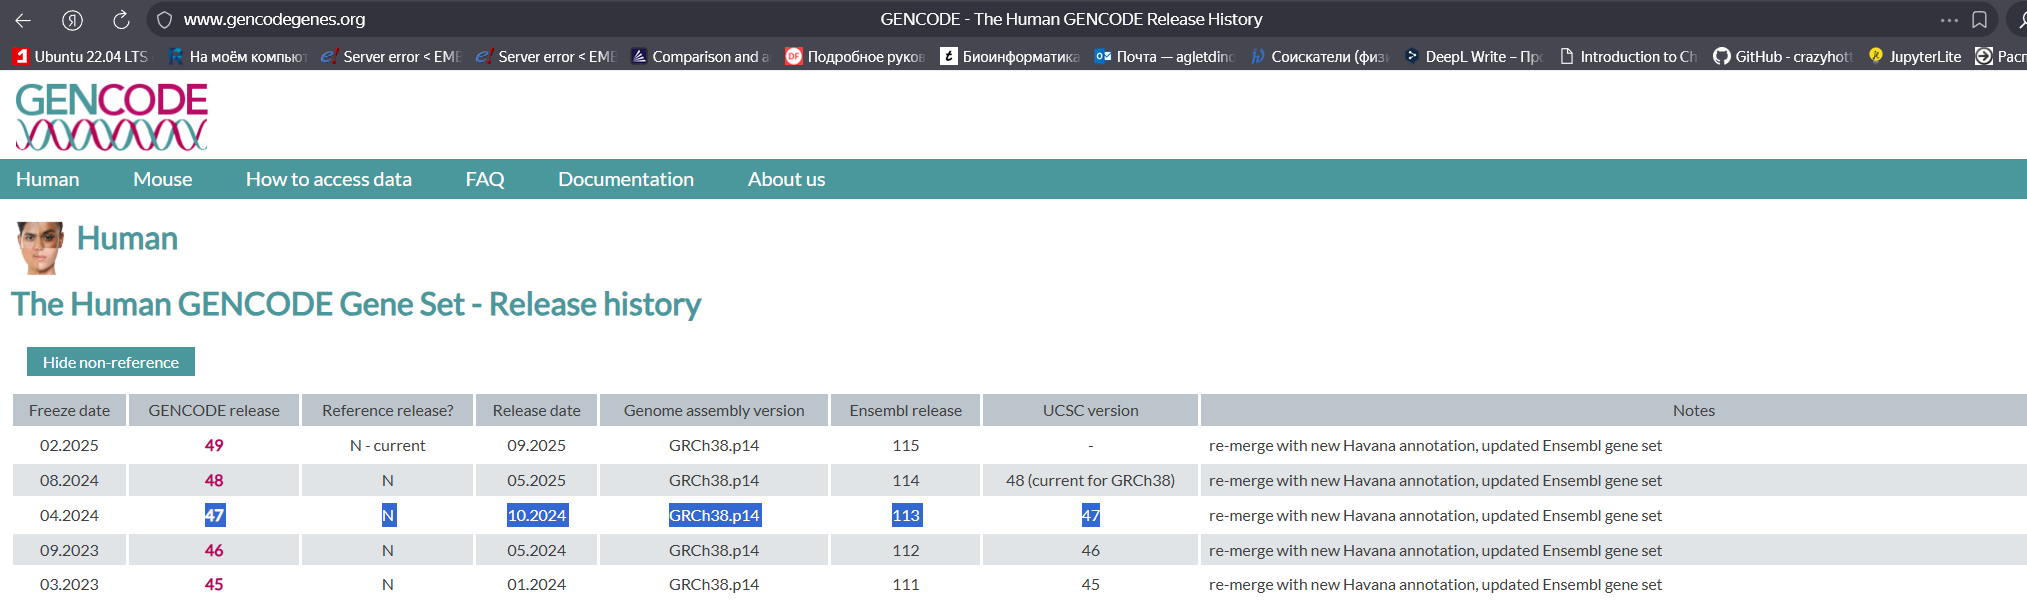

In [5]:
!mamba run -n work mamba list | grep "pybedtools"

  pybedtools                     0.10.0          py312ha1f7cf2_2          bioconda   


In [25]:
def count_genome_coverage(anno, genome="hg38"):
    anno_bed_sort = pybedtools.BedTool.from_dataframe(anno).sort()
    genome_coverage = anno_bed_sort.genome_coverage(bga=True, genome=genome)
    genome_coverage = genome_coverage.to_dataframe()
    genome_coverage["segment_lenght"] = genome_coverage["end"] - genome_coverage["start"]
    res = genome_coverage[genome_coverage["name"] != 0]["segment_lenght"].sum()
    return round(res / 3209286105 * 100, 2) # 3209286105 bp - размер генома человека

In [26]:
!ls {ANNO}

bacterias
FANTOM_CAT.lv2_permissive.gtf.gz
gencode.v19.annotation.gtf.gz
gencode.v25.annotation.gtf.gz
gencode.v31.annotation.gtf.gz
gencode.v31.chr_patch_hapl_scaff.annotation.gtf.gz
Homo_sapiens.GRCh37.87.chr_patch_hapl_scaff.gtf.gz
vzv


In [101]:
!wget https://fantom.gsc.riken.jp/5/suppl/Hon_et_al_2016/data/assembly/lv2_permissive/FANTOM_CAT.lv2_permissive.gtf.gz -O {FANTOM_INITIAL}/FANTOM_CAT.lv2_permissive.gtf.gz

--2024-12-22 17:31:36--  https://fantom.gsc.riken.jp/5/suppl/Hon_et_al_2016/data/assembly/lv2_permissive/FANTOM_CAT.lv2_permissive.gtf.gz
Resolving fantom.gsc.riken.jp (fantom.gsc.riken.jp)... 134.160.84.66
Connecting to fantom.gsc.riken.jp (fantom.gsc.riken.jp)|134.160.84.66|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 51139024 (49M) [application/x-gzip]
Saving to: ‘/export/home/agletdinov/work/git_projects/fantom.deg-himorna.peaks/data_initial/fantom_cat/FANTOM_CAT.lv2_permissive.gtf.gz’

100%[======================================>] 51,139,024  8.86MB/s   in 7.9s   

2024-12-22 17:31:46 (6.21 MB/s) - ‘/export/home/agletdinov/work/git_projects/fantom.deg-himorna.peaks/data_initial/fantom_cat/FANTOM_CAT.lv2_permissive.gtf.gz’ saved [51139024/51139024]



В репозитории fantom.gsc.riken.jp есть файлы bed, tsv а также gtf. Проверили все, наиболее удобно работать с FANTOM_CAT.lv2_permissive.gtf.gz

!wget https://fantom.gsc.riken.jp/5/suppl/Hon_et_al_2016/data/other_data/GENCODEv25_overlay/FANTOM_CAT.overlay_GENCODEv25.transcript.tsv.gz -O {FANTOM_INITIAL}/FANTOM_CAT.overlay_GENCODEv25.gtf.gz

In [17]:
to_overlay_GENCODEv25 = FANTOM_INITIAL / "FANTOM_CAT.overlay_GENCODEv25.gtf.gz" #
FANTOM_overlay_GENCODEv25 = pd.read_csv(to_overlay_GENCODEv25, sep="\t")
FANTOM_overlay_GENCODEv25.head(2)

,trnscptID,geneID,geneType,sameTrnscptStructure_withPartner_IDStr,end3Truncate_withPartner_IDStr,end3Truncate_withinQryOnly_IDStr,nonRedundant
0,ENST00000496771.5_1,ENSG00000000003.14_1,protein_coding,ENST00000496771.1,NaN,NaN,no
1,ENST00000373020.8_1,ENSG00000000003.14_1,protein_coding,ENST00000373020.4,NaN,NaN,no


In [18]:
FANTOM_overlay_GENCODEv25["sameTrnscptStructure_withPartner_IDStr"] = FANTOM_overlay_GENCODEv25["sameTrnscptStructure_withPartner_IDStr"].astype(str)
FANTOM_overlay_GENCODEv25["end3Truncate_withPartner_IDStr"] = FANTOM_overlay_GENCODEv25["end3Truncate_withPartner_IDStr"].astype(str)
FANTOM_overlay_GENCODEv25["end3Truncate_withinQryOnly_IDStr"] = FANTOM_overlay_GENCODEv25["end3Truncate_withinQryOnly_IDStr"].astype(str)

In [19]:
FANTOM_overlay_GENCODEv25.shape

(200052, 7)

In [20]:
FANTOM_overlay_GENCODEv25["geneID_without_v"] = FANTOM_overlay_GENCODEv25["geneID"].apply(lambda x: x.split(".")[0])

In [21]:
FANTOM_overlay_GENCODEv25["geneID_without_v"].nunique()

60162

In [21]:
FANTOM_overlay_GENCODEv25["end3Truncate_withinQryOnly_IDStr"].apply(lambda x: "CAT" in x).sum()

0

In [27]:
gtf_file_FANTOM_l2 = FANTOM_INITIAL / "FANTOM_CAT.lv2_permissive.gtf.gz" #
anno_FANTOM_l2 = pd.read_csv(gtf_file_FANTOM_l2, sep="\t", header=None)
anno_FANTOM_l2.head(2)

,0,1,2,3,4,5,6,7,8
0,chr1,FANTOM,gene,953490,954359,.,+,.,"gene_id ""CATG00000000002.1""; geneSuperClass ""a..."
1,chr1,FANTOM,transcript,953490,954359,.,+,.,"gene_id ""CATG00000000002.1""; transcript_id ""EN..."


In [28]:
anno_FANTOM_l2.shape

(5181581, 9)

In [29]:
anno_FANTOM_l2[0].nunique()

25

In [30]:
anno_FANTOM_l2["ens_gene"] = anno_FANTOM_l2[8].apply(lambda x: x.split(" ")[1].replace('"', '').replace(';', '').split(".")[0])

In [31]:
anno_FANTOM_l2["unique_genome_reg_name"] = anno_FANTOM_l2["ens_gene"] + "-" + anno_FANTOM_l2[2]

In [32]:
fantom_hg19 = anno_FANTOM_l2[[0, 3, 4, "unique_genome_reg_name", 5, 6]]

In [33]:
fantom_hg19.head(2)

,0,3,4,unique_genome_reg_name,5,6
0,chr1,953490,954359,CATG00000000002-gene,.,+
1,chr1,953490,954359,CATG00000000002-transcript,.,+


In [34]:
fantom_hg19.tail()

,0,3,4,unique_genome_reg_name,5,6
5181576,chrY,919238,920858,ENSGR0000225661-gene,.,-
5181577,chrY,919238,920858,ENSGR0000225661-transcript,.,-
5181578,chrY,919238,919286,ENSGR0000225661-exon,.,-
5181579,chrY,919827,920115,ENSGR0000225661-exon,.,-
5181580,chrY,920445,920858,ENSGR0000225661-exon,.,-


Хотим запустить liftOver. Для этого переведем в bed и отсортируем.

In [35]:
fantom_bed_hg19 = pybedtools.BedTool.from_dataframe(fantom_hg19)

In [36]:
len(fantom_bed_hg19)

5181581

In [37]:
fantom_sortbed_hg19 = fantom_bed_hg19.sort()
fantom_sortbed_hg19.head(3)

chr1	91421	762886	ENSG00000225880-transcript	.	-
 chr1	91421	762886	ENSG00000240453-transcript	.	-
 chr1	91421	91629	ENSG00000240453-exon	.	-
 

In [38]:
len(fantom_sortbed_hg19)

5181581

In [19]:
to_save = FANTOM / 'fantom_l2-hg19-sort.bed'
fantom_sortbed_hg19.moveto(to_save)
#fantom_sortbed_hg19.saveas(to_save) - если хотим сохранить переменную fantom_bed_sort

<BedTool(/export/home/agletdinov/work/git_projects/fantom.deg-himorna.peaks/data/fantom_cat/fantom_l2-hg19-sort.bed)>

In [38]:
! wget -O - https://hgdownload.soe.ucsc.edu/goldenPath/hg19/liftOver/hg19ToHg38.over.chain.gz | gunzip -c > {LIFTOVER}/hg19ToHg38.over.chain

--2024-12-22 17:59:06--  https://hgdownload.soe.ucsc.edu/goldenPath/hg19/liftOver/hg19ToHg38.over.chain.gz
Resolving hgdownload.soe.ucsc.edu (hgdownload.soe.ucsc.edu)... 128.114.119.163
Connecting to hgdownload.soe.ucsc.edu (hgdownload.soe.ucsc.edu)|128.114.119.163|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 227698 (222K) [application/x-gzip]
Saving to: ‘STDOUT’

100%[======================================>] 227,698      286KB/s   in 0.8s   

2024-12-22 17:59:09 (286 KB/s) - written to stdout [227698/227698]



In [39]:
!ls /export/home/agletdinov/work/git_projects/fantom.ips-himorna.peaks/data/liftover -ahl

total 600K
drwxrwxr-x  3 agletdinov agletdinov   71 Dec 22  2024 .
drwxrwxr-x 12 agletdinov agletdinov 4.0K Dec 19  2024 ..
-rw-rw-r--  1 agletdinov agletdinov 593K Nov 20  2024 hg19ToHg38.over.chain
drwxrwxr-x  2 agletdinov agletdinov   53 Nov 24  2024 .ipynb_checkpoints


mamba create -n liftover ucsc-liftover -y

In [120]:
!mamba run -n liftover mamba list

List of packages in environment: "/export/home/agletdinov/miniforge3/envs/liftover"

  Name               Version     Build                 Channel    
────────────────────────────────────────────────────────────────────
  _libgcc_mutex      0.1         conda_forge           conda-forge
  _openmp_mutex      4.5         2_gnu                 conda-forge
  ca-certificates    2024.12.14  hbcca054_0            conda-forge
  ld_impl_linux-64   2.43        h712a8e2_2            conda-forge
  libffi             3.4.2       h7f98852_5            conda-forge
  libgcc             14.2.0      h77fa898_1            conda-forge
  libgcc-ng          14.2.0      h69a702a_1            conda-forge
  libgomp            14.2.0      h77fa898_1            conda-forge
  libnsl             2.0.1       hd590300_0            conda-forge
  libopenssl-static  3.4.0       hb9d3cd8_0            conda-forge
  libpng             1.6.43      h2797004_0            conda-forge
  libsqlite          3.46.0      hde9e2c9_

In [84]:
to_hg19_bed = FANTOM / 'fantom_l2-hg19-sort.bed'
to_hg38_bed = FANTOM / 'fantom_l2-hg38.bed'
!mamba run -n liftover liftOver {to_hg19_bed} {LIFTOVER}/hg19ToHg38.over.chain {to_hg38_bed} {FANTOM}/unmaped.bed

Reading liftover chains
Mapping coordinates


In [40]:
to_file = FANTOM / 'fantom_l2-hg38.bed'
fantom_sortbed_hg38 = pybedtools.BedTool(to_file).sort()
fantom_sortbed_hg38.head(3)

chr1	91421	91629	ENSG00000225880-exon	.	-
 chr1	91421	91629	ENSG00000240453-exon	.	-
 chr1	92091	92240	ENSG00000240453-exon	.	-
 

In [41]:
len(fantom_sortbed_hg38)

5179138

In [87]:
to_save = FANTOM / 'fantom_l2-hg38-sort.bed'
fantom_sortbed_hg38.saveas(to_save)#целевой финальный файл

<BedTool(/export/home/agletdinov/work/git_projects/fantom.deg-himorna.peaks/data/fantom_cat/fantom_l2-hg38-sort.bed)>

### Посмотрим на процент покрытости генома

In [43]:
fantom_hg38 = fantom_sortbed_hg38.to_dataframe()
fantom_hg38.head(3)

,chrom,start,end,name,score,strand
0,chr1,91421,91629,ENSG00000225880-exon,.,-
1,chr1,91421,91629,ENSG00000240453-exon,.,-
2,chr1,92091,92240,ENSG00000240453-exon,.,-


In [44]:
fantom_hg38.shape

(5179138, 6)

In [90]:
count_genome_coverage(anno=fantom_hg19)#before migration to hg38 (hg19)

70.06

In [132]:
count_genome_coverage(anno=fantom_hg19, genome='hg19')#before migration to hg38 (hg19)

70.4

In [91]:
count_genome_coverage(anno=fantom_hg38)#after migration to hg38 (hg38)

70.14

Как видно, разница незначительная - ничего серьезного при переносе координат не сломалось

In [45]:
mask = fantom_hg38["name"].apply(lambda x: "gene" in x)
fantom_genes_hg38 = fantom_hg38[mask]
fantom_genes_hg38.head(2)

,chrom,start,end,name,score,strand
5,chr1,159537,162485,CATG00000042730-gene,.,-
14,chr1,273882,274416,CATG00000042731-gene,.,-


In [668]:
mask = fantom_genes_hg38["name"].apply(lambda x: "ENSG00000158623" in x)
fantom_genes_hg38[mask]

,chrom,start,end,name,score,strand,actual_name


In [46]:
fantom_genes_hg38.shape

(123997, 6)

In [47]:
fantom_genes_hg38 = fantom_genes_hg38.drop_duplicates()
fantom_genes_hg38.shape

(123997, 6)

In [95]:
count_genome_coverage(anno=fantom_genes_hg38)#покрытость генами

69.91

In [48]:
fantom_genes_sortbed_hg38 = pybedtools.BedTool.from_dataframe(fantom_genes_hg38).sort()

In [49]:
len(fantom_genes_sortbed_hg38)

123997

In [98]:
to_save = FANTOM / 'fantom_l2_genes-hg38-sort.bed'
#fantom_genes_sortbed_hg38.moveto(to_save)
fantom_genes_sortbed_hg38.saveas(to_save) #- если хотим сохранить переменную fantom_genes_sortbed_hg38

<BedTool(/export/home/agletdinov/work/git_projects/fantom.deg-himorna.peaks/data/fantom_cat/fantom_l2_genes-hg38-sort.bed)>

In [38]:
mask = fantom_hg38["name"].apply(lambda x: "exon" in x)
fantom_exon_hg38 = fantom_hg38[mask]
fantom_exon_hg38.head(2)

,chrom,start,end,name,score,strand
0,chr1,91421,91629,ENSG00000225880-exon,.,-
1,chr1,91421,91629,ENSG00000240453-exon,.,-


In [39]:
fantom_exon_hg38.shape

(4343510, 6)

In [101]:
count_genome_coverage(anno=fantom_exon_hg38)#покрытость экзонами

19.23

## Попытка соотнести гены FANTOM l2 с генами из gencode после миграции

Стратегия заключается в пересечении двух наборов координат и подсчету индекса Жаккара. Посоветовал @GrigoryRyabykh 

In [693]:
def gencode_gtf_processing(to_gtf_file):
    gtf_file_GENCODE = to_gtf_file
    anno_GENCODE = pd.read_csv(gtf_file_GENCODE, sep="\t", header=None, skiprows=5)
    anno_GENCODE["ens_gene"] = anno_GENCODE[8].apply(lambda x: x.split(" ")[1].replace('"', '').replace(';', '').split(".")[0])
    anno_GENCODE["gene_name"] = anno_GENCODE[8].apply(lambda x: x.split("gene_name")[1].split(" ")[1].replace('"', '').replace(';', ''))
    anno_GENCODE["unique_genome_reg_name"] = anno_GENCODE["ens_gene"] + "-" + anno_GENCODE[2]
    gencode_hg38 = anno_GENCODE[[0, 3, 4, "unique_genome_reg_name", 5, 6, "ens_gene", "gene_name"]]
    mask = gencode_hg38["unique_genome_reg_name"].apply(lambda x: "gene" in x)
    gencode_genes_hg38 = gencode_hg38[mask]
    gencode_genes_hg38.head(2)
    gencode_genes_hg38 = gencode_genes_hg38.rename(columns={0:"chrom", 3:"start", 4:"end", "unique_genome_reg_name":"name", 5:"score", 6:"strand"})
    gencode_genes_hg38 = gencode_genes_hg38.drop_duplicates()
    gencode_genes_hg38 = gencode_genes_hg38.drop_duplicates()
    gencode_genes_hg38["gene_ens--gene_name"] = gencode_genes_hg38["ens_gene"] + "--" + gencode_genes_hg38["gene_name"]
    return gencode_genes_hg38

In [694]:
gtf_file_GENCODE = GENCODE_INITIAL / "gencode.v47.basic.annotation.gtf.gz"
gencode_genes_hg38 = gencode_gtf_processing(gtf_file_GENCODE)
gencode_genes_hg38

,chrom,start,end,name,score,strand,ens_gene,gene_name,gene_ens--gene_name
0,chr1,11121,24894,ENSG00000290825-gene,.,+,ENSG00000290825,DDX11L16,ENSG00000290825--DDX11L16
6,chr1,12010,13670,ENSG00000223972-gene,.,+,ENSG00000223972,DDX11L1,ENSG00000223972--DDX11L1
14,chr1,14356,30744,ENSG00000310526-gene,.,-,ENSG00000310526,WASH7P,ENSG00000310526--WASH7P
108,chr1,14696,24886,ENSG00000227232-gene,.,-,ENSG00000227232,WASH7P,ENSG00000227232--WASH7P
120,chr1,17369,17436,ENSG00000278267-gene,.,-,ENSG00000278267,MIR6859-1,ENSG00000278267--MIR6859-1
...,...,...,...,...,...,...,...,...,...
2225559,chrM,14149,14673,ENSG00000198695-gene,.,-,ENSG00000198695,MT-ND6,ENSG00000198695--MT-ND6
2225564,chrM,14674,14742,ENSG00000210194-gene,.,-,ENSG00000210194,MT-TE,ENSG00000210194--MT-TE
2225567,chrM,14747,15887,ENSG00000198727-gene,.,+,ENSG00000198727,MT-CYB,ENSG00000198727--MT-CYB
2225572,chrM,15888,15953,ENSG00000210195-gene,.,+,ENSG00000210195,MT-TT,ENSG00000210195--MT-TT


In [695]:
gencode_genes_bed_hg38 = pybedtools.BedTool.from_dataframe(gencode_genes_hg38[["chrom","start","end","name","score","strand"]])

In [696]:
len(gencode_genes_bed_hg38)

78724

In [697]:
gencode_genes_sortbed_hg38 = gencode_genes_bed_hg38.sort()
gencode_genes_sortbed_hg38.head(3)

chr1	11121	24894	ENSG00000290825-gene	.	+
 chr1	12010	13670	ENSG00000223972-gene	.	+
 chr1	14356	30744	ENSG00000310526-gene	.	-
 

In [698]:
len(gencode_genes_sortbed_hg38)

78724

In [117]:
to_save = GENCODE / 'gencode_genes-hg38-sort.bed'
#gencode_genes_sortbed_hg38.moveto(to_save)
gencode_genes_sortbed_hg38.saveas(to_save) #- если хотим сохранить переменную gencode_genes_sortbed_hg38

<BedTool(/export/home/agletdinov/work/git_projects/fantom.deg-himorna.peaks/data/gencode/gencode_genes-hg38-sort.bed)>

In [55]:
to_file = FANTOM / 'fantom_l2_genes-hg38-sort.bed'
fantom_genes_sortbed_hg38 = pybedtools.BedTool(to_file)

In [90]:
fantom_genes_sortbed_hg38.head(2)

chr1	159537	162485	CATG00000042730-gene	.	-
 chr1	273882	274416	CATG00000042731-gene	.	-
 

In [91]:
len(fantom_genes_sortbed_hg38)

123997

In [92]:
gencode_genes_sortbed_hg38.head(2)

chr1	11121	24894	ENSG00000290825-gene	.	+
 chr1	12010	13670	ENSG00000223972-gene	.	+
 

In [93]:
len(gencode_genes_sortbed_hg38)

78724

### Пересечем все гены из обоих сборок друг с другом

In [94]:
fantom_genes_sortbed_hg38.head(1)

chr1	159537	162485	CATG00000042730-gene	.	-
 

In [96]:
len(fantom_genes_sortbed_hg38)

123997

In [97]:
gencode_genes_sortbed_hg38.head(1)

chr1	11121	24894	ENSG00000290825-gene	.	+
 

In [98]:
len(gencode_genes_sortbed_hg38)

78724

In [115]:
#fantom_overlap_gencode_hg38_bad = fantom_genes_sortbed_hg38_bad.intersect(gencode_genes_sortbed_hg38_bad, wao=True, s=True)
fantom_overlap_gencode_hg38 = fantom_genes_sortbed_hg38.intersect(gencode_genes_sortbed_hg38, wao=True, s=True)

In [116]:
fantom_overlap_gencode_hg38 = fantom_overlap_gencode_hg38.to_dataframe(disable_auto_names=True, header=None)

In [117]:
fantom_overlap_gencode_hg38

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,chr1,159537,162485,CATG00000042730-gene,.,-,chr1,146386,199861,ENSG00000310528-gene,.,-,2948
1,chr1,159537,162485,CATG00000042730-gene,.,-,chr1,89295,181719,ENSG00000241860-gene,.,-,2948
2,chr1,273882,274416,CATG00000042731-gene,.,-,chr1,257864,359681,ENSG00000292994-gene,.,-,534
3,chr1,588120,634563,CATG00000042732-gene,.,-,chr1,632325,632413,ENSG00000278791-gene,.,-,88
4,chr1,588120,634563,CATG00000042732-gene,.,-,chr1,586054,633129,ENSG00000293331-gene,.,-,45009
...,...,...,...,...,...,...,...,...,...,...,...,...,...
171445,chrY,56838851,56850959,CATG00000115125-gene,.,-,.,-1,-1,.,-1,.,0
171446,chrY,56855491,56858320,CATG00000114976-gene,.,+,.,-1,-1,.,-1,.,0
171447,chrY,56855793,56856102,CATG00000115126-gene,.,-,.,-1,-1,.,-1,.,0
171448,chrY,56867675,56882339,CATG00000114977-gene,.,+,chrY,56881849,56882115,ENSG00000305394-gene,.,+,266


In [119]:
56882339 - 56882115	

224

In [114]:
fantom_overlap_gencode_hg38[3].nunique()

84117

### Пересечем только те гены, у которых явно нет аналогов по ens_id для обоих сборок

In [60]:
fantom_genes_hg38.head(1)

,chrom,start,end,name,score,strand
5,chr1,159537,162485,CATG00000042730-gene,.,-


In [61]:
fantom_genes_hg38.shape

(123997, 6)

In [62]:
gencode_genes_hg38.head(1)

,chrom,start,end,name,score,strand
0,chr1,11121,24894,ENSG00000290825-gene,.,+


In [63]:
gencode_genes_hg38.shape

(78724, 6)

In [64]:
merge = pd.merge(left=fantom_genes_hg38, right=gencode_genes_hg38, left_on=["name"], right_on=["name"], how='outer', indicator=True)
merge.head(2)

,chrom_x,start_x,end_x,name,score_x,strand_x,chrom_y,start_y,end_y,score_y,strand_y,_merge
0,chr1,1018110.0,1018979.0,CATG00000000002-gene,.,+,NaN,NaN,NaN,NaN,NaN,left_only
1,chr1,4661850.0,4664407.0,CATG00000000003-gene,.,+,NaN,NaN,NaN,NaN,NaN,left_only


In [65]:
merge[merge["_merge"] == "both"].shape

(35613, 12)

In [81]:
merge["_merge"].value_counts()

_merge
left_only     88384
right_only    43111
both          35613
Name: count, dtype: int64

In [82]:
 merge[merge["_merge"] == "both"]

,chrom_x,start_x,end_x,name,score_x,strand_x,chrom_y,start_y,end_y,score_y,strand_y,_merge
85716,chrX,100605350.0,100668325.0,ENSG00000000003-gene,.,-,chrX,100627108.0,100639991.0,.,-,both
85717,chrX,100584936.0,100601156.0,ENSG00000000005-gene,.,+,chrX,100584936.0,100599885.0,.,+,both
85718,chr20,50934709.0,50958550.0,ENSG00000000419-gene,.,-,chr20,50934867.0,50959140.0,.,-,both
85719,chr1,169809254.0,169894267.0,ENSG00000000457-gene,.,-,chr1,169849631.0,169894267.0,.,-,both
85720,chr1,169745489.0,169873544.0,ENSG00000000460-gene,.,+,chr1,169662007.0,169854080.0,.,+,both
...,...,...,...,...,...,...,...,...,...,...,...,...
139795,chr9,134164983.0,134172005.0,ENSG00000273473-gene,.,+,chr9,134168769.0,134169340.0,.,+,both
139800,chr1,112517799.0,112518518.0,ENSG00000273483-gene,.,-,chr1,112517799.0,112518441.0,.,-,both
139802,chr10,103448777.0,103451349.0,ENSG00000273485-gene,.,+,chr10,103450196.0,103450852.0,.,+,both
139804,chr1,92188438.0,92190708.0,ENSG00000273487-gene,.,+,chr1,92189237.0,92190707.0,.,+,both


In [66]:
merge_unique = merge[merge["_merge"] != "both"]
merge_unique.shape

(131495, 12)

In [86]:
merge_unique[["start_x", "end_x"]] = merge_unique[["start_x", "end_x"]].astype(int, errors="ignore")

/tmp/ipykernel_6526/2451818103.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  merge_unique[["start_x", "end_x"]] = merge_unique[["start_x", "end_x"]].astype(int, errors="ignore")


In [67]:
fantom_genes_hg38_bad = merge_unique[merge_unique["_merge"] == "left_only"][["chrom_x","start_x","end_x","name","score_x","strand_x"]]
fantom_genes_hg38_bad.head(2)

,chrom_x,start_x,end_x,name,score_x,strand_x
0,chr1,1018110.0,1018979.0,CATG00000000002-gene,.,+
1,chr1,4661850.0,4664407.0,CATG00000000003-gene,.,+


In [68]:
fantom_genes_hg38_bad.shape

(88384, 6)

In [69]:
fantom_genes_hg38_bad[["start_x", "end_x"]] = fantom_genes_hg38_bad[["start_x", "end_x"]].astype(int)

In [70]:
gencode_genes_hg38_bad = merge_unique[merge_unique["_merge"] == "right_only"][["chrom_y","start_y","end_y","name","score_y","strand_y"]]
gencode_genes_hg38_bad.head(2)

,chrom_y,start_y,end_y,name,score_y,strand_y
86062,chrX,150361422.0,150514178.0,ENSG00000013619-gene,.,+
86102,chr2,132309309.0,132318736.0,ENSG00000018607-gene,.,+


In [71]:
gencode_genes_hg38_bad.shape

(43111, 6)

In [72]:
gencode_genes_hg38_bad[["start_y", "end_y"]] = gencode_genes_hg38_bad[["start_y", "end_y"]].astype(int)

In [73]:
gencode_genes_sortbed_hg38_bad = pybedtools.BedTool.from_dataframe(gencode_genes_hg38_bad).sort()

In [74]:
fantom_genes_sortbed_hg38_bad = pybedtools.BedTool.from_dataframe(fantom_genes_hg38_bad).sort()

In [97]:
#fantom_overlap_gencode_hg38_bad = fantom_genes_sortbed_hg38_bad.intersect(gencode_genes_sortbed_hg38_bad, wao=True, s=True)
fantom_overlap_gencode_hg38_bad = fantom_genes_sortbed_hg38_bad.intersect(gencode_genes_sortbed_hg38, wao=True, s=True)

In [98]:
fantom_overlap_gencode_hg38_bad = fantom_overlap_gencode_hg38_bad.to_dataframe(disable_auto_names=True, header=None)

In [99]:
fantom_overlap_gencode_hg38_bad.head(2)

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,chr1,159537,162485,CATG00000042730-gene,.,-,chr1,146386,199861,ENSG00000310528-gene,.,-,2948
1,chr1,159537,162485,CATG00000042730-gene,.,-,chr1,89295,181719,ENSG00000241860-gene,.,-,2948


In [100]:
len(fantom_overlap_gencode_hg38_bad)

98105

In [101]:
#f - fantom
#g - gencode

In [102]:
fantom_overlap_gencode_hg38_bad = fantom_overlap_gencode_hg38_bad.rename(columns={0:"f-chrom", 1:"f-strart", 2:"f-end", 3:"f-name", 4:"f-score", 5:"f-strand",
                                            6:"g-chrom", 7:"g-strart", 8:"g-end", 9:"g-name", 10:"g-score", 11:"g-strand",
                                            12:"overlap"})

In [103]:
%%time
fantom_overlap_gencode_hg38_bad["merge_len"] = fantom_overlap_gencode_hg38_bad[["f-strart", "f-end", "g-strart", "g-end"]].max(axis=1) - fantom_overlap_gencode_hg38_bad[["f-strart", "f-end", "g-strart", "g-end"]].min(axis=1)

CPU times: user 45.1 ms, sys: 423 μs, total: 45.6 ms
Wall time: 43.1 ms


In [104]:
fantom_overlap_gencode_hg38_bad["jaccard"] = fantom_overlap_gencode_hg38_bad["overlap"] / fantom_overlap_gencode_hg38_bad["merge_len"]

In [105]:
fantom_overlap_gencode_hg38_bad["long_ot_short_genes_pair"] = np.where(fantom_overlap_gencode_hg38_bad["merge_len"] >= 50000, "long", "short")

In [106]:
mask = np.where(
    ((fantom_overlap_gencode_hg38_bad["long_ot_short_genes_pair"] == "short") & (fantom_overlap_gencode_hg38_bad["jaccard"] > 0.7)) |
    ((fantom_overlap_gencode_hg38_bad["long_ot_short_genes_pair"] == "long") & ((fantom_overlap_gencode_hg38_bad["merge_len"] - fantom_overlap_gencode_hg38_bad["overlap"]) < 5000)),
    True, False
)

In [107]:
fantom_overlap_gencode_hg38_bad_signif = fantom_overlap_gencode_hg38_bad[mask]
fantom_overlap_gencode_hg38_bad_signif.head(2)

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,long_ot_short_genes_pair
4,chr1,588120,634563,CATG00000042732-gene,.,-,chr1,586054,633129,ENSG00000293331-gene,.,-,45009,48509,0.927848,short
16,chr1,980904,989798,CATG00000079600-gene,.,+,chr1,982505,989967,ENSG00000303599-gene,.,+,7293,9063,0.804700,short


In [108]:
fantom_overlap_gencode_hg38_bad_signif.shape

(3465, 16)

In [109]:
fantom_overlap_gencode_hg38_bad_signif

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,long_ot_short_genes_pair
4,chr1,588120,634563,CATG00000042732-gene,.,-,chr1,586054,633129,ENSG00000293331-gene,.,-,45009,48509,0.927848,short
16,chr1,980904,989798,CATG00000079600-gene,.,+,chr1,982505,989967,ENSG00000303599-gene,.,+,7293,9063,0.804700,short
39,chr1,1348603,1362484,CATG00000033020-gene,.,+,chr1,1348183,1362350,ENSG00000304860-gene,.,+,13747,14301,0.961261,short
78,chr1,2033502,2047379,CATG00000043697-gene,.,-,chr1,2033503,2047450,ENSG00000304958-gene,.,-,13876,13948,0.994838,short
94,chr1,2385404,2388507,ENSG00000178642-gene,.,+,chr1,2385375,2388508,ENSG00000295371-gene,.,+,3103,3133,0.990425,short
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97979,chrY,12661208,12663471,CATG00000115079-gene,.,-,chrY,12661309,12663540,ENSG00000286009-gene,.,-,2162,2332,0.927101,short
98024,chrY,16599730,16644509,CATG00000115092-gene,.,-,chrY,16599730,16644539,ENSG00000286201-gene,.,-,44779,44809,0.999330,short
98036,chrY,19076189,19089629,CATG00000114916-gene,.,+,chrY,19076134,19087061,ENSG00000310485-gene,.,+,10872,13495,0.805632,short
98043,chrY,19868845,19884156,CATG00000114922-gene,.,+,chrY,19868842,19884157,ENSG00000300595-gene,.,+,15311,15315,0.999739,short


In [110]:
fantom_overlap_gencode_hg38_bad_signif["f-name"].nunique()

3447

In [111]:
fantom_overlap_gencode_hg38_bad_signif.groupby(by="f-name").aggregate(
          number_of_comapped_genes=("g-name", "nunique")   
    ).query("number_of_comapped_genes > 1")

,number_of_comapped_genes
f-name,
CATG00000001224-gene,2
CATG00000005574-gene,2
CATG00000007600-gene,2
CATG00000021186-gene,2
CATG00000026748-gene,2
CATG00000040180-gene,2
CATG00000052816-gene,2
CATG00000090889-gene,2
CATG00000095955-gene,2


In [156]:
fantom_overlap_gencode_hg38_bad_signif.groupby(by="f-name").aggregate(
          number_of_comapped_genes=("g-name", "nunique")   
    ).query("number_of_comapped_genes == 1").shape

(3429, 1)

In [112]:
multimapped_genes = fantom_overlap_gencode_hg38_bad_signif.groupby(by="f-name").aggregate(
          number_of_comapped_genes=("g-name", "nunique")   
    ).query("number_of_comapped_genes > 1").index.to_list()
multimapped_genes

['CATG00000001224-gene',
 'CATG00000005574-gene',
 'CATG00000007600-gene',
 'CATG00000021186-gene',
 'CATG00000026748-gene',
 'CATG00000040180-gene',
 'CATG00000052816-gene',
 'CATG00000090889-gene',
 'CATG00000095955-gene',
 'ENSG00000187667-gene',
 'ENSG00000199769-gene',
 'ENSG00000226894-gene',
 'ENSG00000236669-gene',
 'ENSG00000237102-gene',
 'ENSG00000239492-gene',
 'ENSG00000252808-gene',
 'ENSG00000254782-gene',
 'ENSG00000269900-gene']

In [155]:
mask = fantom_overlap_gencode_hg38_bad_signif["f-name"].apply(lambda x: x in multimapped_genes)
fantom_overlap_gencode_hg38_bad_signif[mask].shape

(36, 16)

In [114]:
fantom_overlap_gencode_hg38_bad_signif = fantom_overlap_gencode_hg38_bad_signif.reset_index(drop=True)

In [115]:
fantom_overlap_gencode_hg38_bad_signif.loc[fantom_overlap_gencode_hg38_bad_signif.groupby('f-name')['jaccard'].idxmax()]

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,long_ot_short_genes_pair
385,chr10,69442344,69451962,CATG00000000017-gene,.,-,chr10,69442453,69451315,ENSG00000299501-gene,.,-,8862,9618,0.921397,short
386,chr10,71472957,71474054,CATG00000000075-gene,.,-,chr10,71472878,71474189,ENSG00000301241-gene,.,-,1097,1311,0.836766,short
387,chr10,71702887,71709248,CATG00000000078-gene,.,-,chr10,71704424,71709248,ENSG00000300551-gene,.,-,4824,6361,0.758371,short
388,chr10,71776622,71783290,CATG00000000081-gene,.,-,chr10,71776544,71783291,ENSG00000306531-gene,.,-,6668,6747,0.988291,short
391,chr10,78151004,78176805,CATG00000000214-gene,.,-,chr10,78148447,78176822,ENSG00000294914-gene,.,-,25801,28375,0.909286,short
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3451,chrY,333963,386913,ENSGR0000167393-gene,.,-,chrY,333933,386955,ENSG00000292327-gene,.,-,52950,53022,0.998642,long
3453,chrY,1403139,1452888,ENSGR0000169093-gene,.,-,chrY,1403139,1453762,ENSG00000292339-gene,.,-,49749,50623,0.982735,long
3454,chrY,1462572,1537185,ENSGR0000182162-gene,.,-,chrY,1462581,1537185,ENSG00000292333-gene,.,-,74604,74613,0.999879,long
3455,chrY,2486414,2502817,ENSGR0000214717-gene,.,-,chrY,2486414,2500976,ENSG00000292345-gene,.,-,14562,16403,0.887764,short


И того, удалось восстановить 3348 генов (если пересекать gencode_bad и fantom_bad).\
Если пересекать fantom_bad со всеми из gencode, то число восттановленных генов - 3447.

In [149]:
fantom_overlap_gencode_hg38 = fantom_genes_sortbed_hg38.intersect(gencode_genes_sortbed_hg38, wao=True, s=True)

In [156]:
fantom_overlap_gencode_hg38 = fantom_overlap_gencode_hg38.to_dataframe(disable_auto_names=True, header=None)

In [159]:
fantom_overlap_gencode_hg38.head(2)

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,chr1,159537,162485,CATG00000042730-gene,.,-,chr1,146386,199861,ENSG00000310528-gene,.,-,2948
1,chr1,159537,162485,CATG00000042730-gene,.,-,chr1,89295,181719,ENSG00000241860-gene,.,-,2948


In [160]:
len(fantom_overlap_gencode_hg38)

171450

In [161]:
#f - fantom
#g - gencode

In [163]:
fantom_overlap_gencode_hg38 = fantom_overlap_gencode_hg38.rename(columns={0:"f-chrom", 1:"f-strart", 2:"f-end", 3:"f-name", 4:"f-score", 5:"f-strand",
                                            6:"g-chrom", 7:"g-strart", 8:"g-end", 9:"g-name", 10:"g-score", 11:"g-strand",
                                            12:"overlap"})

In [170]:
%%time
fantom_overlap_gencode_hg38["merge_len"] = fantom_overlap_gencode_hg38[["f-strart", "f-end", "g-strart", "g-end"]].max(axis=1) - fantom_overlap_gencode_hg38[["f-strart", "f-end", "g-strart", "g-end"]].min(axis=1)

CPU times: user 71 ms, sys: 3 ms, total: 74 ms
Wall time: 70.7 ms


In [199]:
fantom_overlap_gencode_hg38["jaccard"] = fantom_overlap_gencode_hg38["overlap"] / fantom_overlap_gencode_hg38["merge_len"]

In [214]:
fantom_overlap_gencode_hg38["long_ot_short_genes_pair"] = np.where(fantom_overlap_gencode_hg38["merge_len"] >= 50000, "long", "short")

In [330]:
mask = np.where(
    ((fantom_overlap_gencode_hg38["long_ot_short_genes_pair"] == "short") & (fantom_overlap_gencode_hg38["jaccard"] > 0.7)) |
    ((fantom_overlap_gencode_hg38["long_ot_short_genes_pair"] == "long") & ((fantom_overlap_gencode_hg38["merge_len"] - fantom_overlap_gencode_hg38["overlap"]) < 5000)),
    True, False
)

In [337]:
y = []
for i in [0, 0.1, 0.2,0.3,0.4,0.5,0.6,0.7,0.8, 0.9, 1]:
    mask = np.where(
    ((fantom_overlap_gencode_hg38["long_ot_short_genes_pair"] == "short") & (fantom_overlap_gencode_hg38["jaccard"] > i)) |
    ((fantom_overlap_gencode_hg38["long_ot_short_genes_pair"] == "long") & ((fantom_overlap_gencode_hg38["merge_len"] - fantom_overlap_gencode_hg38["overlap"]) < 5000)),
    True, False
).sum()
    print(mask)
    y.append(mask.sum())

56118
40521
35270
31629
28679
26055
23492
20793
17654
13592
3674


<Axes: >

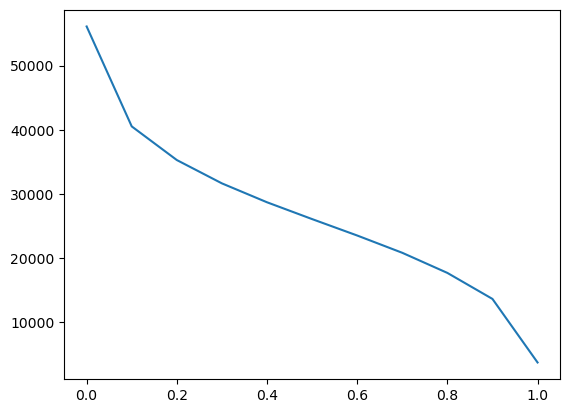

In [338]:
x = [0, 0.1, 0.2,0.3,0.4,0.5,0.6,0.7,0.8, 0.9, 1]
y = y
sns.lineplot(x=x, y=y)

In [318]:
fantom_overlap_gencode_hg38_signif = fantom_overlap_gencode_hg38[mask]
fantom_overlap_gencode_hg38_signif.head(2)

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,long_ot_short_genes_pair
4,chr1,588120,634563,CATG00000042732-gene,.,-,chr1,586054,633129,ENSG00000293331-gene,.,-,45009,48509,0.927848,short
23,chr1,631381,632616,ENSG00000237973-gene,.,+,chr1,631074,632616,ENSG00000237973-gene,.,+,1235,1542,0.800908,short


In [326]:
fantom_overlap_gencode_hg38_signif.shape

(20793, 16)

In [327]:
fantom_overlap_gencode_hg38_signif["f-name"].apply(lambda x: "CAT" in x).sum()

3089

In [328]:
fantom_overlap_gencode_hg38_signif["f-name"].apply(lambda x: "ENSG" in x).sum()

17704

(0.0, 1.0)

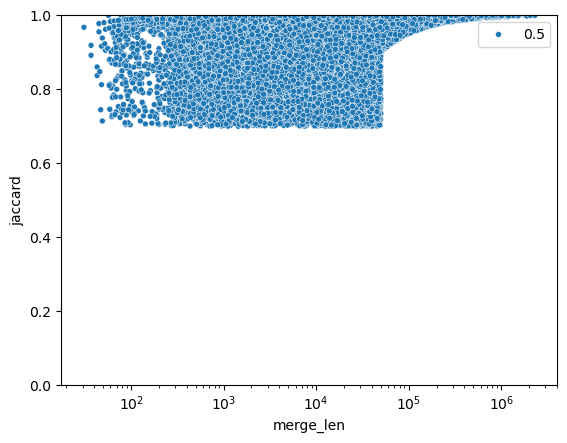

In [320]:
sns.scatterplot(data=fantom_overlap_gencode_hg38_signif, x="merge_len", y="jaccard", size=0.5)
plt.xscale('log')
plt.ylim(0, 1)

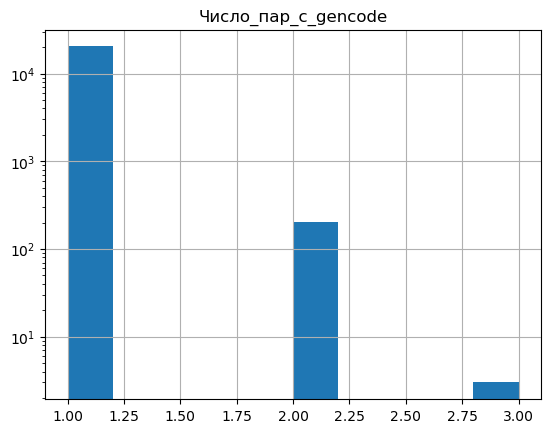

In [321]:
number_of_fantom_gencode_pairs = fantom_overlap_gencode_hg38_signif.groupby(by="f-name").aggregate(
    Число_пар_с_gencode=("g-name", "nunique")
).sort_values(by="Число_пар_с_gencode", ascending=False)
number_of_fantom_gencode_pairs.hist()
plt.yscale('log')

In [322]:
mask = fantom_overlap_gencode_hg38_signif["f-name"].isin(number_of_fantom_gencode_pairs[number_of_fantom_gencode_pairs["Число_пар_с_gencode"] > 1].index)
fantom_overlap_gencode_hg38_signif[mask]

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,long_ot_short_genes_pair
1206,chr1,16035178,16040365,ENSG00000232456-gene,.,-,chr1,16034513,16039902,ENSG00000307216-gene,.,-,4724,5852,0.807245,short
1207,chr1,16035178,16040365,ENSG00000232456-gene,.,-,chr1,16035178,16040029,ENSG00000232456-gene,.,-,4851,5187,0.935223,short
1491,chr1,19597015,19658056,ENSG00000270136-gene,.,+,chr1,19596979,19658456,ENSG00000158747-gene,.,+,61041,61477,0.992908,long
1492,chr1,19597015,19658056,ENSG00000270136-gene,.,+,chr1,19597067,19656927,ENSG00000270136-gene,.,+,59860,61041,0.980652,long
2384,chr1,28648600,28648733,ENSG00000270103-gene,.,+,chr1,28648600,28648733,ENSG00000274978-gene,.,+,133,133,1.000000,short
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
167337,chrX,48432914,48442975,ENSG00000235350-gene,.,+,chrX,48433449,48442980,ENSG00000296579-gene,.,+,9526,10066,0.946354,short
167550,chrX,52624101,52634419,ENSG00000157965-gene,.,+,chrX,52622935,52633948,ENSG00000290686-gene,.,+,9847,11484,0.857454,short
167551,chrX,52624101,52634419,ENSG00000157965-gene,.,+,chrX,52624998,52632891,ENSG00000157965-gene,.,+,7893,10318,0.764974,short
168064,chrX,70846081,70846298,ENSG00000199769-gene,.,-,chrX,70846079,70846295,ENSG00000277492-gene,.,-,214,219,0.977169,short


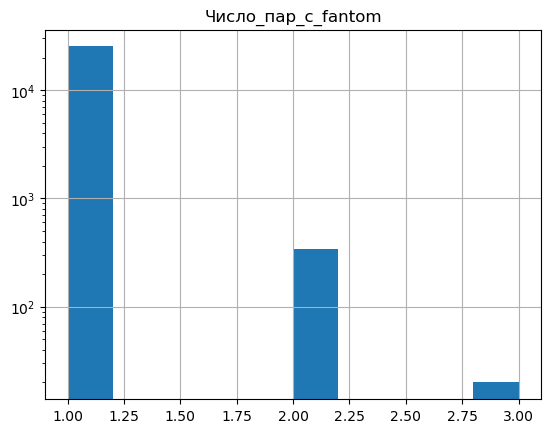

In [292]:
fantom_overlap_gencode_hg38_signif.groupby(by="g-name").aggregate(
    Число_пар_с_fantom=("f-name", "nunique")
).sort_values(by="Число_пар_с_fantom", ascending=False).hist()
plt.yscale('log')

In [ ]:
Посмотри, сколько однозначно определится, кто отвалится. Точно отвалятся все ребята с merge_len > 5000000bp

In [266]:
fantom_overlap_gencode_hg38[fantom_overlap_gencode_hg38["jaccard"] > 0.5]

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard,long_ot_short_genes_pair
4,chr1,588120,634563,CATG00000042732-gene,.,-,chr1,586054,633129,ENSG00000293331-gene,.,-,45009,48509,0.927848,short
17,chr1,630001,630683,ENSG00000225630-gene,.,+,chr1,629640,630683,ENSG00000225630-gene,.,+,682,1043,0.653883,short
23,chr1,631381,632616,ENSG00000237973-gene,.,+,chr1,631074,632616,ENSG00000237973-gene,.,+,1235,1542,0.800908,short
26,chr1,632814,633438,ENSG00000229344-gene,.,+,chr1,632757,633438,ENSG00000229344-gene,.,+,624,681,0.916300,short
27,chr1,633535,633741,ENSG00000240409-gene,.,+,chr1,633535,633741,ENSG00000240409-gene,.,+,206,206,1.000000,short
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
171387,chrY,20575725,20594534,ENSG00000198692-gene,.,+,chrY,20575776,20593154,ENSG00000198692-gene,.,+,17378,18809,0.923919,short
171388,chrY,20756139,20781085,ENSG00000157828-gene,.,+,chrY,20756108,20781032,ENSG00000280969-gene,.,+,24893,24977,0.996637,short
171389,chrY,20808776,20811982,ENSG00000224482-gene,.,-,chrY,20808776,20811809,ENSG00000224482-gene,.,-,3033,3206,0.946039,short
171422,chrY,25723344,25723495,ENSG00000252426-gene,.,+,chrY,25723342,25723495,ENSG00000252426-gene,.,+,151,153,0.986928,short


In [268]:
fantom_genes_hg38[fantom_genes_hg38["name"] == ""]

,chrom,start,end,name,score,strand
5,chr1,159537,162485,CATG00000042730-gene,.,-
14,chr1,273882,274416,CATG00000042731-gene,.,-
26,chr1,588120,634563,CATG00000042732-gene,.,-
27,chr1,627377,629095,ENSG00000223659-gene,.,-
34,chr1,629083,634376,ENSG00000248527-gene,.,+
...,...,...,...,...,...,...
5179074,chrY,56838851,56850959,CATG00000115125-gene,.,-
5179122,chrY,56855491,56858320,CATG00000114976-gene,.,+
5179126,chrY,56855793,56856102,CATG00000115126-gene,.,-
5179130,chrY,56867675,56882339,CATG00000114977-gene,.,+


In [ ]:
fantom_overlap_gencode_hg38[(fantom_overlap_gencode_hg38["long_ot_short_genes_pair"])]

In [201]:
fantom_overlap_gencode_hg38.head(3)

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard
0,chr1,159537,162485,CATG00000042730-gene,.,-,chr1,146386,199861,ENSG00000310528-gene,.,-,2948,53475,0.055129
1,chr1,159537,162485,CATG00000042730-gene,.,-,chr1,89295,181719,ENSG00000241860-gene,.,-,2948,92424,0.031896
2,chr1,273882,274416,CATG00000042731-gene,.,-,chr1,257864,359681,ENSG00000292994-gene,.,-,534,101817,0.005245


In [207]:
fantom_overlap_gencode_hg38[fantom_overlap_gencode_hg38["f-name"] == "CATG00000042730-gene"]

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard
0,chr1,159537,162485,CATG00000042730-gene,.,-,chr1,146386,199861,ENSG00000310528-gene,.,-,2948,53475,0.055129
1,chr1,159537,162485,CATG00000042730-gene,.,-,chr1,89295,181719,ENSG00000241860-gene,.,-,2948,92424,0.031896


In [211]:
fantom_overlap_gencode_hg38[fantom_overlap_gencode_hg38["f-name"] == "ENSG00000225470-gene"]

,f-chrom,f-strart,f-end,f-name,f-score,f-strand,g-chrom,g-strart,g-end,g-name,g-score,g-strand,overlap,merge_len,jaccard
168282,chrX,73944326,74070408,ENSG00000225470-gene,.,+,chrX,73944332,73944466,ENSG00000274430-gene,.,+,134,126082,0.001063
168283,chrX,73944326,74070408,ENSG00000225470-gene,.,+,chrX,73944595,73944663,ENSG00000276784-gene,.,+,68,126082,0.000539
168284,chrX,73944326,74070408,ENSG00000225470-gene,.,+,chrX,74031462,74031820,ENSG00000233984-gene,.,+,358,126082,0.002839
168285,chrX,73944326,74070408,ENSG00000225470-gene,.,+,chrX,74066083,74066592,ENSG00000203397-gene,.,+,509,126082,0.004037
168286,chrX,73944326,74070408,ENSG00000225470-gene,.,+,chrX,74069276,74070832,ENSG00000234969-gene,.,+,1132,126506,0.008948
168287,chrX,73944326,74070408,ENSG00000225470-gene,.,+,chrX,73943934,74070423,ENSG00000225470-gene,.,+,126082,126489,0.996782


<Axes: >

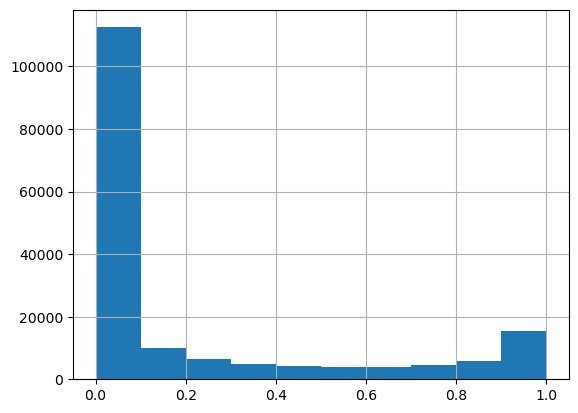

In [212]:
fantom_overlap_gencode_hg38["jaccard"].hist()

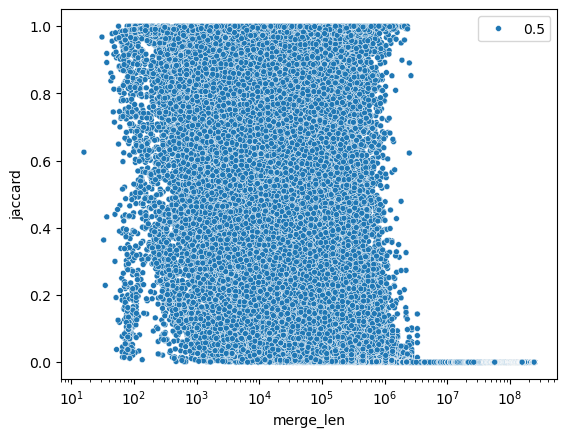

In [206]:
sns.scatterplot(data=fantom_overlap_gencode_hg38, x="merge_len", y="jaccard", size=0.5)
plt.xscale('log')

## Проверка ENSG* генов после миграции

Некоторые ENSG* не переживают миграцию на новую сборку. Они могут пропасть/трансформироваться в новые ENSG*.
Если оставить все как есть, то может возникнуть ситуация, когда мы представим файл "fantom_hg38", а на самом деле там будут содержаться индентификаторы, которых уже нет в  GRCh38.

In [634]:
!wget https://ftp.ensembl.org/pub/release-113/gtf/homo_sapiens/Homo_sapiens.GRCh38.113.chr.gtf.gz -O {ENSEMBL_INITIAL}/Homo_sapiens.GRCh38.113.chr.gtf.gz

--2025-12-01 16:33:36--  https://ftp.ensembl.org/pub/release-115/gtf/homo_sapiens/Homo_sapiens.GRCh38.115.chr.gtf.gz
Resolving ftp.ensembl.org (ftp.ensembl.org)... 193.62.193.169
Connecting to ftp.ensembl.org (ftp.ensembl.org)|193.62.193.169|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 104303351 (99M) [application/x-gzip]
Saving to: ‘/export/home/agletdinov/work/git_projects/fantom.deg-himorna.peaks/data_initial/ensembl/Homo_sapiens.GRCh38.115.chr.gtf.gz’

100%[======================================>] 104,303,351 19.5MB/s   in 7.8s   

2025-12-01 16:33:44 (12.7 MB/s) - ‘/export/home/agletdinov/work/git_projects/fantom.deg-himorna.peaks/data_initial/ensembl/Homo_sapiens.GRCh38.115.chr.gtf.gz’ saved [104303351/104303351]



In [651]:
gtf_file_ensembl = ENSEMBL_INITIAL / "Homo_sapiens.GRCh38.113.chr.gtf.gz"
anno_ensembl = pd.read_csv(gtf_file_ensembl, sep="\t", skiprows=5, header=None, dtype={0:str})#важно указать тип для chr. Иначе появляются дубли. F.e. 1 и "1"
anno_ensembl.head(2)

,0,1,2,3,4,5,6,7,8
0,1,ensembl_havana,gene,3069168,3438621,.,+,.,"gene_id ""ENSG00000142611""; gene_version ""17""; ..."
1,1,havana,transcript,3069168,3434342,.,+,.,"gene_id ""ENSG00000142611""; gene_version ""17""; ..."


In [652]:
anno_ensembl.shape

(4102290, 9)

In [653]:
anno_ensembl[0].nunique()

25

In [654]:
anno_ensembl[0] = anno_ensembl[0].apply(lambda x: "M" if x == "MT" else x)
anno_ensembl[0] = anno_ensembl[0].apply(lambda x: "chr" + x)

In [655]:
anno_ensembl["ens_gene"] = anno_ensembl[8].apply(lambda x: x.split(" ")[1].replace('"', '').replace(';', '').split(".")[0])

In [656]:
anno_ensembl["unique_genome_reg_name"] = anno_ensembl["ens_gene"] + "-" + anno_ensembl[2]

In [657]:
ensembl_hg38 = anno_ensembl[[0, 3, 4, "unique_genome_reg_name"]]

In [658]:
ensembl_hg38 = ensembl_hg38.rename(columns={0:"chr", 3:"start", 4:"end", "unique_genome_reg_name":"name"})

In [659]:
mask = ensembl_hg38["name"].apply(lambda x: "gene" in x)
ensembl_genes_hg38 = ensembl_hg38[mask].reset_index(drop=True)
ensembl_genes_hg38.head(2)

,chr,start,end,name
0,chr1,3069168,3438621,ENSG00000142611-gene
1,chr1,5301928,5307394,ENSG00000284616-gene


In [660]:
ensembl_genes_hg38 = ensembl_genes_hg38.drop_duplicates()

In [661]:
ensembl_genes_hg38.shape

(78724, 4)

In [669]:
mask = ensembl_genes_hg38["name"].apply(lambda x: "ENSG00000158623" in x)
ensembl_genes_hg38[mask]

,chr,start,end,name
29206,chr7,130506238,130668748,ENSG00000158623-gene


In [646]:
count_genome_coverage(anno=ensembl_hg38)

64.32

In [647]:
count_genome_coverage(anno=ensembl_genes_hg38)

64.32

In [66]:
count_genome_coverage(anno=gencode_genes_hg38)

64.23

In [662]:
mask = fantom_genes_hg38["name"].apply(lambda x: "ENSG" in x)
fantom_ensgenes_hg38 = fantom_genes_hg38[mask]
fantom_ensgenes_hg38.head(2)

,chrom,start,end,name,score,strand,actual_name
27,chr1,627377,629095,ENSG00000223659-gene,.,-,<retired>
34,chr1,629083,634376,ENSG00000248527-gene,.,+,ENSG00000248527-gene


In [663]:
fantom_ensgenes_hg38.shape

(38281, 7)

In [664]:
len(set(ensembl_genes_hg38["name"]) - set(fantom_ensgenes_hg38["name"]))#ENSG* гены, которых изначально не было в fantom_l2_hg19

43111

In [665]:
bad_genes = set(fantom_ensgenes_hg38["name"]) - set(ensembl_genes_hg38["name"])#ENSG* гены, которые по каким-то причинам не пережили миграцию с ensembl_hg19 на ensembl_hg38
len(bad_genes)

2668

In [491]:
bad_genes

{'ENSG00000251144-gene',
 'ENSG00000253256-gene',
 'ENSG00000232018-gene',
 'ENSG00000250588-gene',
 'ENSG00000205047-gene',
 'ENSG00000238646-gene',
 'ENSG00000266862-gene',
 'ENSG00000263182-gene',
 'ENSG00000235702-gene',
 'ENSG00000260951-gene',
 'ENSG00000264326-gene',
 'ENSG00000269410-gene',
 'ENSG00000253248-gene',
 'ENSG00000186530-gene',
 'ENSG00000161570-gene',
 'ENSG00000221521-gene',
 'ENSG00000256316-gene',
 'ENSG00000165390-gene',
 'ENSG00000266408-gene',
 'ENSG00000268032-gene',
 'ENSG00000267161-gene',
 'ENSG00000216109-gene',
 'ENSG00000233147-gene',
 'ENSG00000199004-gene',
 'ENSG00000238822-gene',
 'ENSG00000214556-gene',
 'ENSG00000239594-gene',
 'ENSG00000263264-gene',
 'ENSG00000271751-gene',
 'ENSG00000187456-gene',
 'ENSG00000267268-gene',
 'ENSG00000184551-gene',
 'ENSG00000273373-gene',
 'ENSG00000234610-gene',
 'ENSG00000265710-gene',
 'ENSG00000130489-gene',
 'ENSG00000237189-gene',
 'ENSG00000250606-gene',
 'ENSG00000056661-gene',
 'ENSG00000213922-gene',


Именно эти 2668 идентификатор генов необходимо перевести на hg38, если это возможно. Для этого воспользуемся id_history_converter. \
Он входит в набор программ ensembl-tools: https://github.com/Ensembl/ensembl-tools/tree/release/99 \
Для уставки: \
git clone git@github.com:Ensembl/ensembl-tools.git \
mamba create -n ensembl-tools -y \
mamba install perl-app-cpanminus -y \
cpanm Bio::EnsEMBL

Проверим, есть ли разница, если использовать не ensembl аннотацию, а gencode

In [85]:
bad_genes_gencode = set(fantom_ensgenes_hg38["name"]) - set(gencode_genes_hg38["name"])#ENSG* гены, которые по каким-то причинам не пережили миграцию с ensembl_hg19 на gencode_hg38
len(bad_genes_gencode)

2668

Результат идентичен

In [168]:
set(fantom_ensgenes_hg38["name"]) - set(ensembl_genes_hg38["name"])

{'ENSG00000236716-gene',
 'ENSG00000233255-gene',
 'ENSG00000212734-gene',
 'ENSG00000232018-gene',
 'ENSG00000230265-gene',
 'ENSG00000251044-gene',
 'ENSG00000240929-gene',
 'ENSG00000273478-gene',
 'ENSG00000260824-gene',
 'ENSG00000267759-gene',
 'ENSG00000235934-gene',
 'ENSG00000251274-gene',
 'ENSG00000225373-gene',
 'ENSG00000221181-gene',
 'ENSG00000247844-gene',
 'ENSG00000267643-gene',
 'ENSG00000238425-gene',
 'ENSGR0000169100-gene',
 'ENSG00000238564-gene',
 'ENSG00000268885-gene',
 'ENSG00000221211-gene',
 'ENSG00000264576-gene',
 'ENSG00000269783-gene',
 'ENSG00000270581-gene',
 'ENSG00000265072-gene',
 'ENSG00000264790-gene',
 'ENSG00000266398-gene',
 'ENSG00000104725-gene',
 'ENSG00000224512-gene',
 'ENSG00000264421-gene',
 'ENSG00000244349-gene',
 'ENSG00000261534-gene',
 'ENSG00000236673-gene',
 'ENSG00000256248-gene',
 'ENSG00000240524-gene',
 'ENSG00000258941-gene',
 'ENSG00000260071-gene',
 'ENSG00000256323-gene',
 'ENSG00000212998-gene',
 'ENSG00000265500-gene',


In [265]:
with open(f"{ID_HISTORY_CONVERTER_RES}/bad_genes-id.txt", "w") as file:
    file.writelines("%s\n" % line.split("-")[0] for line in bad_genes)

In [298]:
to_script_dir = "/export/home/agletdinov/work/git_projects/ensembl-tools/scripts/id_history_converter"

In [178]:
!mamba run -n ensembl-tools perl {to_script_dir}/IDmapper.pl -s human -f {ID_HISTORY_CONVERTER_RES}/bad_genes-id.txt > {ID_HISTORY_CONVERTER_RES}/bad_genes-history.txt

warning  libmamba You have not set the root prefix environment variable.
    To permanently modify the root prefix location, either:
      - set the 'MAMBA_ROOT_PREFIX' environment variable
      - use the '-r,--root-prefix' CLI option
      - use 'mamba shell init ...' to initialize your shell
        (then restart or source the contents of the shell init script)
    Continuing with default value: "/export/home/agletdinov/miniforge3"


with open(f"{ID_HISTORY_CONVERTER_RES}/bad_genes-history.txt", "r") as f:
    bad_genes_history = f.readlines()

In [712]:
bad_genes_history = pd.read_csv(f"{ID_HISTORY_CONVERTER_RES}/bad_genes-history.txt", skipinitialspace=True)
bad_genes_history = bad_genes_history.rename(columns=lambda x: x.strip())
bad_genes_history

,Old stable ID,New stable ID,Release,Mapping score
0,ENSG00000236716.1,ENSG00000236716.1,98,0.9
1,ENSG00000236716.1,ENSG00000236716.1,99,0.9
2,ENSG00000236716.1,ENSG00000236716.1,100,0.9
3,ENSG00000236716.1,ENSG00000232624.9,113,0.99
4,Old stable ID,New stable ID,Release,Mapping score
...,...,...,...,...
10686,Old stable ID,New stable ID,Release,Mapping score
10687,ENSG00000232505.1,ENSG00000232505.2,73,0.716602
10688,ENSG00000232505.2,<retired>,90,0
10689,Old stable ID,New stable ID,Release,Mapping score


In [493]:
mask = bad_genes_history["Old stable ID"].apply(lambda x: "ENSG" in x)
bad_genes_history = bad_genes_history[mask].reset_index(drop=True)

In [494]:
bad_genes_history["Old stable ID without v"] = bad_genes_history["Old stable ID"].apply(lambda x: x.split(".")[0])
bad_genes_history["New stable ID without v"] = bad_genes_history["New stable ID"].apply(lambda x: x.split(".")[0])

In [495]:
bad_genes_history.head(2)

,Old stable ID,New stable ID,Release,Mapping score,Old stable ID without v,New stable ID without v
0,ENSG00000236716.1,ENSG00000236716.1,98,0.9,ENSG00000236716,ENSG00000236716
1,ENSG00000236716.1,ENSG00000236716.1,99,0.9,ENSG00000236716,ENSG00000236716


In [496]:
bad_genes_history["Old stable ID without v"].nunique()

2661

In [497]:
bad_genes_history

,Old stable ID,New stable ID,Release,Mapping score,Old stable ID without v,New stable ID without v
0,ENSG00000236716.1,ENSG00000236716.1,98,0.9,ENSG00000236716,ENSG00000236716
1,ENSG00000236716.1,ENSG00000236716.1,99,0.9,ENSG00000236716,ENSG00000236716
2,ENSG00000236716.1,ENSG00000236716.1,100,0.9,ENSG00000236716,ENSG00000236716
3,ENSG00000236716.1,ENSG00000232624.9,113,0.99,ENSG00000236716,ENSG00000232624
4,ENSG00000233255.1,<retired>,88,0,ENSG00000233255,<retired>
...,...,...,...,...,...,...
8019,ENSG00000257603.1,ENSG00000257603.1,100,0.9,ENSG00000257603,ENSG00000257603
8020,ENSG00000257603.1,ENSG00000257997.6,113,0.99,ENSG00000257603,ENSG00000257997
8021,ENSG00000232505.1,ENSG00000232505.2,73,0.716602,ENSG00000232505,ENSG00000232505
8022,ENSG00000232505.2,<retired>,90,0,ENSG00000232505,<retired>


In [498]:
ensgr_bad_genes = set([i.split("-")[0] for i in bad_genes]) - set(bad_genes_history["Old stable ID without v"].unique())
len(ensgr_bad_genes)

7

In [499]:
bad_genes_history["Release"] = bad_genes_history["Release"].astype(float)

In [500]:
def check_retired_conditions(df):
    # Находим все строки с <retired>
    df = df.reset_index(drop=True)
    retired_rows = df[df['New stable ID without v'] == '<retired>']
    if len(retired_rows) == 0:
        return False
    # Проверка 1: что <retired> только в одном экземпляре
    is_single_instance = len(retired_rows) == 1
    
    # Получаем индекс строки с <retired>
    retired_index = retired_rows.index[0]
    total_rows = len(df)
    
    # Проверка 2: что <retired> не на последней строке
    is_not_last = retired_index != total_rows - 1
    
    # Проверка 3: что <retired> не на предпоследней строке  
    is_not_second_last = retired_index != total_rows - 2
    if is_not_second_last == False:
        if df.iloc[retired_index, 2] == df.iloc[retired_index-1, 2]:
            is_not_second_last = True
    if is_single_instance & is_not_last & is_not_second_last:
        return True
    return False

In [434]:
check_retired_conditions(bad_genes_history.query(f"`Old stable ID without v` == 'ENSG00000243135'"))

False

In [501]:
#нужно модифицировать функцию для случаев, когда ген вырождается в несколько
def bad_history_analyzer(ensg_id, bad_genes_history):
    query_res = bad_genes_history.query(f"`Old stable ID without v` == '{ensg_id}'")
    query_res_length = len(query_res)
    if query_res_length == 0:
        new_ensg = "<retired>"
        return new_ensg
    if check_retired_conditions(df=query_res):
        new_ensg = "<retired>-to-many"
        return new_ensg
    else:
        new_ensg = query_res.iloc[-1, 5]
    return new_ensg

In [502]:
bad_history_analyzer(ensg_id="ENSG00000251144", bad_genes_history=bad_genes_history)

'ENSG00000251670'

In [507]:
bad_genes_resolutions = {i.split("-")[0]:bad_history_analyzer(ensg_id=i.split("-")[0], bad_genes_history=bad_genes_history) for i in bad_genes}

In [508]:
len(bad_genes_resolutions)

2668

In [509]:
bad_genes_resolutions

{'ENSG00000251144': 'ENSG00000251670',
 'ENSG00000253256': 'ENSG00000253315',
 'ENSG00000232018': '<retired>',
 'ENSG00000250588': '<retired>',
 'ENSG00000205047': '<retired>',
 'ENSG00000238646': '<retired>',
 'ENSG00000266862': '<retired>',
 'ENSG00000263182': '<retired>',
 'ENSG00000235702': '<retired>',
 'ENSG00000260951': 'ENSG00000233824',
 'ENSG00000264326': '<retired>',
 'ENSG00000269410': '<retired>',
 'ENSG00000253248': '<retired>',
 'ENSG00000186530': '<retired>',
 'ENSG00000161570': '<retired>',
 'ENSG00000221521': '<retired>',
 'ENSG00000256316': '<retired>-to-many',
 'ENSG00000165390': '<retired>',
 'ENSG00000266408': '<retired>',
 'ENSG00000268032': '<retired>',
 'ENSG00000267161': '<retired>',
 'ENSG00000216109': '<retired>',
 'ENSG00000233147': '<retired>',
 'ENSG00000199004': '<retired>',
 'ENSG00000238822': '<retired>',
 'ENSG00000214556': '<retired>',
 'ENSG00000239594': '<retired>',
 'ENSG00000263264': '<retired>',
 'ENSG00000271751': 'ENSG00000272186',
 'ENSG00000

In [589]:
df_bad_genes_resolutions = pd.DataFrame({"name":bad_genes_resolutions.keys(), "name_latest":bad_genes_resolutions.values()})
df_bad_genes_resolutions

,name,name_latest
0,ENSG00000251144,ENSG00000251670
1,ENSG00000253256,ENSG00000253315
2,ENSG00000232018,<retired>
3,ENSG00000250588,<retired>
4,ENSG00000205047,<retired>
...,...,...
2663,ENSG00000267893,<retired>
2664,ENSG00000253381,ENSG00000253665
2665,ENSG00000249091,ENSG00000248397
2666,ENSG00000226785,<retired>


In [511]:
Counter(df_bad_genes_resolutions["name_latest"])["<retired>"]

2157

In [512]:
Counter(df_bad_genes_resolutions["name_latest"])["<retired>-to-many"]

43

In [534]:
mask = df_bad_genes_resolutions["name"] == df_bad_genes_resolutions["name_latest"]# почти все из них также устарели
df_bad_genes_resolutions_also_retired = df_bad_genes_resolutions[mask]
df_bad_genes_resolutions_also_retired

,name,name_latest
60,ENSG00000233937,ENSG00000233937
342,ENSG00000252239,ENSG00000252239
518,ENSG00000240042,ENSG00000240042
829,ENSG00000226277,ENSG00000226277
851,ENSG00000238102,ENSG00000238102
1001,ENSG00000258081,ENSG00000258081
1049,ENSG00000173876,ENSG00000173876
1053,ENSG00000249069,ENSG00000249069
1582,ENSG00000252379,ENSG00000252379
1860,ENSG00000234698,ENSG00000234698


In [520]:
mask = (df_bad_genes_resolutions["name"] != df_bad_genes_resolutions["name_latest"]) & (df_bad_genes_resolutions["name_latest"] != "<retired>") & (df_bad_genes_resolutions["name_latest"] != "<retired>-to-many")
df_bad_genes_ok1

,name,name_latest
0,ENSG00000251144,ENSG00000251670
1,ENSG00000253256,ENSG00000253315
9,ENSG00000260951,ENSG00000233824
28,ENSG00000271751,ENSG00000272186
32,ENSG00000273373,ENSG00000224699
...,...,...
2650,ENSG00000239332,ENSG00000222005
2656,ENSG00000230649,ENSG00000232053
2664,ENSG00000253381,ENSG00000253665
2665,ENSG00000249091,ENSG00000248397


In [584]:
df_bad_genes_resolutions["name_latest"].to_list()

['ENSG00000251670',
 'ENSG00000253315',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 'ENSG00000233824',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>-to-many',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 'ENSG00000272186',
 '<retired>',
 '<retired>',
 '<retired>',
 'ENSG00000224699',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 'ENSG00000261617',
 '<retired>',
 '<retired>',
 '<retired>',
 'ENSG00000271086',
 '<retired>',
 'ENSG00000258819',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 'ENSG00000263400',
 'ENSG00000272975',
 '<retired>',
 'ENSG00000233937',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '<retired>',
 '

In [585]:
with open(f"{ID_HISTORY_CONVERTER_RES}/bad_genes-id-second_iteration.txt", "w") as file:
    file.writelines("%s\n" % line for line in df_bad_genes_resolutions["name_latest"].to_list())

In [303]:
!mamba run -n ensembl-tools perl {to_script_dir}/IDmapper.pl -s human -f {ID_HISTORY_CONVERTER_RES}/bad_genes-id_second_iteration.txt > {ID_HISTORY_CONVERTER_RES}/bad_genes-history-second_iteration.txt

^C


In [305]:
#на самом деле я не дождался выполнения скрипта. Исполбзую результат из веб версии: https://www.ensembl.org/Homo_sapiens/Tools/IDMapper/Results?tl=8H58UhpePHZA6f5x-11480280

In [522]:
bad_genes_history_iter2 = pd.read_csv(f"{ID_HISTORY_CONVERTER_RES}/bad_genes-history-second_iteration_web.txt", skipinitialspace=True)
bad_genes_history_iter2 = bad_genes_history_iter2.rename(columns=lambda x: x.strip())
bad_genes_history_iter2

,Old stable ID,New stable ID,Release,Mapping score
0,ENSG00000251670.1,ENSG00000251670.1,98,0.9
1,ENSG00000251670.1,ENSG00000251670.1,99,0.9
2,ENSG00000251670.1,ENSG00000251670.1,100,0.9
3,ENSG00000251670.1,ENSG00000251670.2,113,0.99
4,Old stable ID,New stable ID,Release,Mapping score
...,...,...,...,...
6119,ENSG00000266473.1,ENSG00000266473.1,92,0.72
6120,ENSG00000266473.1,ENSG00000266473.1,98,0.9
6121,ENSG00000266473.1,ENSG00000266473.1,99,0.9
6122,ENSG00000266473.1,ENSG00000266473.1,100,0.9


In [523]:
mask = bad_genes_history_iter2["Old stable ID"].apply(lambda x: "ENSG" in x)
bad_genes_history_iter2 = bad_genes_history_iter2[mask].reset_index(drop=True)

In [524]:
bad_genes_history_iter2["Old stable ID without v"] = bad_genes_history_iter2["Old stable ID"].apply(lambda x: x.split(".")[0])
bad_genes_history_iter2["New stable ID without v"] = bad_genes_history_iter2["New stable ID"].apply(lambda x: x.split(".")[0])

In [525]:
bad_genes_history_iter2["Old stable ID without v"].nunique()

438

In [526]:
bad_genes_history_iter2["Release"] = bad_genes_history_iter2["Release"].astype(float)

In [527]:
bad_genes_resolutions_iter2 = {i:bad_history_analyzer(ensg_id=i, bad_genes_history=bad_genes_history_iter2) for i in bad_genes_history_iter2["Old stable ID without v"].unique()}

In [529]:
df_bad_genes_resolutions_iter2 = pd.DataFrame({"name":bad_genes_resolutions_iter2.keys(), "name_latest":bad_genes_resolutions_iter2.values()})
df_bad_genes_resolutions_iter2

,name,name_latest
0,ENSG00000251670,ENSG00000251670
1,ENSG00000253315,ENSG00000253315
2,ENSG00000233824,ENSG00000233824
3,ENSG00000277775,ENSG00000277775
4,ENSG00000272186,ENSG00000272186
...,...,...
433,ENSG00000222005,ENSG00000222005
434,ENSG00000251964,ENSG00000251964
435,ENSG00000232053,ENSG00000232053
436,ENSG00000248397,ENSG00000248397


In [551]:
mask = df_bad_genes_resolutions_iter2["name"] != df_bad_genes_resolutions_iter2["name_latest"]
df_bad_genes_resolutions_iter2_different = df_bad_genes_resolutions_iter2[mask]
df_bad_genes_resolutions_iter2_different

,name,name_latest
13,ENSG00000274622,<retired>
111,ENSG00000281285,<retired>-to-many
112,ENSG00000233143,ENSG00000223874
119,ENSG00000225489,ENSG00000236924
172,ENSG00000277203,<retired>-to-many
207,ENSG00000281751,<retired>-to-many
277,ENSG00000274267,<retired>-to-many
331,ENSG00000279854,<retired>-to-many
348,ENSG00000182230,<retired>
427,ENSG00000274644,<retired>-to-many


In [ ]:
#соберем результаты обновления в одном месте

In [536]:
df_bad_genes_resolutions_also_retired

,name,name_latest
60,ENSG00000233937,ENSG00000233937
342,ENSG00000252239,ENSG00000252239
518,ENSG00000240042,ENSG00000240042
829,ENSG00000226277,ENSG00000226277
851,ENSG00000238102,ENSG00000238102
1001,ENSG00000258081,ENSG00000258081
1049,ENSG00000173876,ENSG00000173876
1053,ENSG00000249069,ENSG00000249069
1582,ENSG00000252379,ENSG00000252379
1860,ENSG00000234698,ENSG00000234698


In [597]:
df_bad_genes_resolutions_final = df_bad_genes_resolutions.copy()

In [598]:
df_bad_genes_resolutions_final["name_latest"] = df_bad_genes_resolutions_final["name_latest"].apply(lambda x: "<retired>" if x in df_bad_genes_resolutions_also_retired["name_latest"].to_list() else x)

In [599]:
Counter(df_bad_genes_resolutions_final["name_latest"])["<retired>"]

2173

In [600]:
Counter(df_bad_genes_resolutions["name_latest"])["<retired>"]

2157

In [601]:
assert len(df_bad_genes_resolutions_also_retired) + Counter(df_bad_genes_resolutions["name_latest"])["<retired>"] == Counter(df_bad_genes_resolutions_final["name_latest"])["<retired>"]

In [602]:
df_bad_genes_resolutions_final

,name,name_latest
0,ENSG00000251144,ENSG00000251670
1,ENSG00000253256,ENSG00000253315
2,ENSG00000232018,<retired>
3,ENSG00000250588,<retired>
4,ENSG00000205047,<retired>
...,...,...
2663,ENSG00000267893,<retired>
2664,ENSG00000253381,ENSG00000253665
2665,ENSG00000249091,ENSG00000248397
2666,ENSG00000226785,<retired>


In [632]:
mask = (df_bad_genes_resolutions_final["name_latest"] != "<retired>") & (df_bad_genes_resolutions_final["name_latest"] != "<retired>-to-many")
df_bad_genes_resolutions_final[mask]

,name,name_latest
0,ENSG00000251144,ENSG00000251670
1,ENSG00000253256,ENSG00000253315
9,ENSG00000260951,ENSG00000233824
28,ENSG00000271751,ENSG00000272186
32,ENSG00000273373,ENSG00000224699
...,...,...
2650,ENSG00000239332,ENSG00000222005
2656,ENSG00000230649,ENSG00000232053
2664,ENSG00000253381,ENSG00000253665
2665,ENSG00000249091,ENSG00000248397


In [608]:
(df_bad_genes_resolutions_final["name"] == df_bad_genes_resolutions_final["name_latest"]).sum()

0

In [604]:
to_file = f"{ID_HISTORY_CONVERTER_RES}/bad_genes-resolutions.tsv"
df_bad_genes_resolutions_final.to_csv(to_file, sep="\t", index=False)

In [607]:
dict_bad_genes_resolutions_final = {i:j for i,j in zip(df_bad_genes_resolutions_final["name"], df_bad_genes_resolutions_final["name_latest"])}
len(dict_bad_genes_resolutions_final)

2668

In [610]:
fantom_genes_hg38["actual_name"] = fantom_genes_hg38["name"].apply(lambda x: dict_bad_genes_resolutions_final[x.split("-")[0]] if x.split("-")[0] in dict_bad_genes_resolutions_final else x)

Добавим инрформацию о gene_name:

In [691]:
fantom_genes_hg38

,chrom,start,end,name,score,strand,actual_name
5,chr1,159537,162485,CATG00000042730-gene,.,-,CATG00000042730-gene
14,chr1,273882,274416,CATG00000042731-gene,.,-,CATG00000042731-gene
26,chr1,588120,634563,CATG00000042732-gene,.,-,CATG00000042732-gene
27,chr1,627377,629095,ENSG00000223659-gene,.,-,<retired>
34,chr1,629083,634376,ENSG00000248527-gene,.,+,ENSG00000248527-gene
...,...,...,...,...,...,...,...
5179074,chrY,56838851,56850959,CATG00000115125-gene,.,-,CATG00000115125-gene
5179122,chrY,56855491,56858320,CATG00000114976-gene,.,+,CATG00000114976-gene
5179126,chrY,56855793,56856102,CATG00000115126-gene,.,-,CATG00000115126-gene
5179130,chrY,56867675,56882339,CATG00000114977-gene,.,+,CATG00000114977-gene


In [703]:
fantom_genes_hg38 = pd.merge(left=fantom_genes_hg38, right=gencode_genes_hg38[["name", "gene_name"]], how="left", left_on="actual_name", right_on="name")
fantom_genes_hg38

,chrom,start,end,name_x,score,strand,actual_name,name_y,gene_name
0,chr1,159537,162485,CATG00000042730-gene,.,-,CATG00000042730-gene,NaN,NaN
1,chr1,273882,274416,CATG00000042731-gene,.,-,CATG00000042731-gene,NaN,NaN
2,chr1,588120,634563,CATG00000042732-gene,.,-,CATG00000042732-gene,NaN,NaN
3,chr1,627377,629095,ENSG00000223659-gene,.,-,<retired>,NaN,NaN
4,chr1,629083,634376,ENSG00000248527-gene,.,+,ENSG00000248527-gene,ENSG00000248527-gene,MTATP6P1
...,...,...,...,...,...,...,...,...,...
123992,chrY,56838851,56850959,CATG00000115125-gene,.,-,CATG00000115125-gene,NaN,NaN
123993,chrY,56855491,56858320,CATG00000114976-gene,.,+,CATG00000114976-gene,NaN,NaN
123994,chrY,56855793,56856102,CATG00000115126-gene,.,-,CATG00000115126-gene,NaN,NaN
123995,chrY,56867675,56882339,CATG00000114977-gene,.,+,CATG00000114977-gene,NaN,NaN


In [706]:
fantom_genes_hg38 = fantom_genes_hg38.drop("name_y", axis=1)

In [708]:
fantom_genes_hg38 = fantom_genes_hg38.rename(columns={"name_x":"name"})

In [710]:
fantom_genes_hg38 = fantom_genes_hg38.rename(columns={"gene_name":"actual_gene_name"})

In [711]:
to_save = FANTOM / 'fantom_l2_genes-hg38-all_info.tsv'
fantom_genes_hg38.to_csv(to_save, sep="\t", index=False)

In [614]:
(fantom_genes_hg38["name"] != fantom_genes_hg38["actual_name"]).sum()

2668

In [616]:
(fantom_genes_hg38["actual_name"] == "<retired>").sum()

2173

In [617]:
(fantom_genes_hg38["actual_name"] == "<retired>-to-many").sum()

43

In [666]:
len(fantom_genes_hg38)

123997

In [630]:
mask = (fantom_genes_hg38["actual_name"] != "<retired>") & (fantom_genes_hg38["actual_name"] != "<retired>-to-many")
fantom_genes_hg38[mask]

,chrom,start,end,name,score,strand,actual_name
5,chr1,159537,162485,CATG00000042730-gene,.,-,CATG00000042730-gene
14,chr1,273882,274416,CATG00000042731-gene,.,-,CATG00000042731-gene
26,chr1,588120,634563,CATG00000042732-gene,.,-,CATG00000042732-gene
34,chr1,629083,634376,ENSG00000248527-gene,.,+,ENSG00000248527-gene
35,chr1,629209,631743,ENSG00000225972-gene,.,+,ENSG00000225972-gene
...,...,...,...,...,...,...,...
5179074,chrY,56838851,56850959,CATG00000115125-gene,.,-,CATG00000115125-gene
5179122,chrY,56855491,56858320,CATG00000114976-gene,.,+,CATG00000114976-gene
5179126,chrY,56855793,56856102,CATG00000115126-gene,.,-,CATG00000115126-gene
5179130,chrY,56867675,56882339,CATG00000114977-gene,.,+,CATG00000114977-gene


In [624]:
mask = (fantom_genes_hg38["actual_name"] != "<retired>") & (fantom_genes_hg38["actual_name"] != "<retired>-to-many")
fantom_genes_hg38_ensg_fixed = fantom_genes_hg38[mask]
fantom_genes_hg38_ensg_fixed = fantom_genes_hg38_ensg_fixed[["chrom","start","end","actual_name", "score","strand"]]
fantom_genes_hg38_ensg_fixed = fantom_genes_hg38_ensg_fixed.rename(columns={"actual_name":"name"})
fantom_genes_hg38_ensg_fixed

,chrom,start,end,name,score,strand
5,chr1,159537,162485,CATG00000042730-gene,.,-
14,chr1,273882,274416,CATG00000042731-gene,.,-
26,chr1,588120,634563,CATG00000042732-gene,.,-
34,chr1,629083,634376,ENSG00000248527-gene,.,+
35,chr1,629209,631743,ENSG00000225972-gene,.,+
...,...,...,...,...,...,...
5179074,chrY,56838851,56850959,CATG00000115125-gene,.,-
5179122,chrY,56855491,56858320,CATG00000114976-gene,.,+
5179126,chrY,56855793,56856102,CATG00000115126-gene,.,-
5179130,chrY,56867675,56882339,CATG00000114977-gene,.,+


In [667]:
to_save = FANTOM / 'fantom_l2_genes-hg38-ensg_fixed.tsv'
fantom_genes_hg38_ensg_fixed.to_csv(to_save, sep="\t", index=False)

In [626]:
fantom_genes_sortbed_hg38_ensg_fixed = pybedtools.BedTool.from_dataframe(fantom_genes_hg38_ensg_fixed).sort()
len(fantom_genes_sortbed_hg38_ensg_fixed)

121781

In [627]:
to_save = FANTOM / 'fantom_l2_genes-hg38-sort-ensg_fixed.bed'
#fantom_genes_sortbed_hg38.moveto(to_save)
fantom_genes_sortbed_hg38_ensg_fixed.saveas(to_save) #- если хотим сохранить переменную fantom_genes_sortbed_hg38_ensg_fixed

<BedTool(/export/home/agletdinov/work/git_projects/fantom.deg-himorna.peaks/data/fantom_cat/fantom_l2_genes-hg38-sort-ensg_fixed.bed)>

## Про вторую итерацию пока что не думаем

In [562]:
dict_bad_genes_resolutions_iter2_different = {i:j for i,j in zip(df_bad_genes_resolutions_iter2_different["name"], df_bad_genes_resolutions_iter2_different["name_latest"])}
dict_bad_genes_resolutions_iter2_different

{'ENSG00000274622': '<retired>',
 'ENSG00000281285': '<retired>-to-many',
 'ENSG00000233143': 'ENSG00000223874',
 'ENSG00000225489': 'ENSG00000236924',
 'ENSG00000277203': '<retired>-to-many',
 'ENSG00000281751': '<retired>-to-many',
 'ENSG00000274267': '<retired>-to-many',
 'ENSG00000279854': '<retired>-to-many',
 'ENSG00000182230': '<retired>',
 'ENSG00000274644': '<retired>-to-many'}

In [583]:
df_bad_genes_resolutions[df_bad_genes_resolutions["name_latest"] == "ENSG00000281751"]

,name,name_latest


In [565]:
df_bad_genes_resolutions_final["name_latest"] = df_bad_genes_resolutions_final["name_latest"].apply(lambda x: dict_bad_genes_resolutions_iter2_different[x] if x in dict_bad_genes_resolutions_iter2_different.keys() else x)

In [566]:
df_bad_genes_resolutions_final

,name,name_latest
0,ENSG00000251144,ENSG00000251670
1,ENSG00000253256,ENSG00000253315
2,ENSG00000232018,<retired>
3,ENSG00000250588,<retired>
4,ENSG00000205047,<retired>
...,...,...
2663,ENSG00000267893,<retired>
2664,ENSG00000253381,ENSG00000253665
2665,ENSG00000249091,ENSG00000248397
2666,ENSG00000226785,<retired>


In [568]:
df_bad_genes_resolutions_final[df_bad_genes_resolutions_final["name"] == df_bad_genes_resolutions_final["name_latest"]]

,name,name_latest


In [574]:
len(df_bad_genes_resolutions_final[df_bad_genes_resolutions_final["name_latest"] == "<retired>"])

2173

In [573]:
len(df_bad_genes_resolutions_final[df_bad_genes_resolutions_final["name_latest"] == "<retired>-to-many"])

43

In [575]:
df_bad_genes_resolutions_final[df_bad_genes_resolutions_final["name"] == "ENSG00000281285"]

,name,name_latest


In [297]:
df_bad_genes_resolutions.query("(name != name_latest) & name_latest != '<retired>'")

,name,name_latest
0,ENSG00000251144-gene,ENSG00000251670
1,ENSG00000253256-gene,ENSG00000253315
9,ENSG00000260951-gene,ENSG00000233824
16,ENSG00000256316-gene,ENSG00000277775
28,ENSG00000271751-gene,ENSG00000272186
...,...,...
2654,ENSG00000251964-gene,ENSG00000251964
2656,ENSG00000230649-gene,ENSG00000232053
2664,ENSG00000253381-gene,ENSG00000253665
2665,ENSG00000249091-gene,ENSG00000248397


In [287]:
[i for i in bad_genes_resolutions.values() if i != "<retired>-gene"]

['ENSG00000251670-gene',
 'ENSG00000253315-gene',
 'ENSG00000233824-gene',
 'ENSG00000277775-gene',
 'ENSG00000272186-gene',
 'ENSG00000224699-gene',
 'ENSG00000261617-gene',
 'ENSG00000271086-gene',
 'ENSG00000258819-gene',
 'ENSG00000263400-gene',
 'ENSG00000272975-gene',
 'ENSG00000233937-gene',
 'ENSG00000267394-gene',
 'ENSG00000274622-gene',
 'ENSG00000261749-gene',
 'ENSG00000224812-gene',
 'ENSG00000280707-gene',
 'ENSG00000235126-gene',
 'ENSG00000232624-gene',
 'ENSG00000241135-gene',
 'ENSG00000251611-gene',
 'ENSG00000291027-gene',
 'ENSG00000239569-gene',
 'ENSG00000290758-gene',
 'ENSG00000146147-gene',
 'ENSG00000189171-gene',
 'ENSG00000236141-gene',
 'ENSG00000224187-gene',
 'ENSG00000260874-gene',
 'ENSG00000267532-gene',
 'ENSG00000231826-gene',
 'ENSG00000254350-gene',
 'ENSG00000257878-gene',
 'ENSG00000212766-gene',
 'ENSG00000223725-gene',
 'ENSG00000270164-gene',
 'ENSG00000286277-gene',
 'ENSG00000301866-gene',
 'ENSG00000262294-gene',
 'ENSG00000286971-gene',


In [261]:
fantom_genes_hg38["actual_name"] = fantom_genes_hg38["name"].apply(lambda x: bad_history_analyzer(ensg_id=x.split("-")[0], bad_genes_history=bad_genes_history)+"-gene" if x in bad_genes else x)

In [263]:
mask = fantom_genes_hg38["name"] != fantom_genes_hg38["actual_name"]
fantom_genes_hg38[mask]

,chrom,start,end,name,score,strand,actual_name
27,chr1,627377,629095,ENSG00000223659-gene,.,-,<retired>-gene
539,chr1,882205,884603,ENSG00000269308-gene,.,+,<retired>-gene
593,chr1,911441,914948,ENSG00000230699-gene,.,+,ENSG00000272438-gene
7943,chr1,1562346,1564858,ENSG00000215791-gene,.,-,<retired>-gene
12391,chr1,2189798,2191740,ENSG00000269554-gene,.,+,<retired>-gene
...,...,...,...,...,...,...,...
5173674,chrY,2486414,2502817,ENSGR0000214717-gene,.,-,<retired>-gene
5174860,chrY,10090634,10091207,ENSG00000235691-gene,.,+,<retired>-gene
5174915,chrY,10195574,10196484,ENSG00000251966-gene,.,+,<retired>-gene
5175438,chrY,12662353,12694644,ENSG00000233864-gene,.,+,<retired>-gene


In [341]:
{i:len(bad_history_analyzer_res[i]) for i in bad_history_analyzer_res}

{'retired': 2566, 'problem': 95}

In [342]:
bad_history_analyzer_res["problem"]

['ENSG00000107618',
 'ENSG00000107623',
 'ENSG00000110347',
 'ENSG00000124529',
 'ENSG00000124693',
 'ENSG00000128802',
 'ENSG00000132139',
 'ENSG00000137259',
 'ENSG00000138293',
 'ENSG00000138294',
 'ENSG00000141150',
 'ENSG00000154768',
 'ENSG00000157828',
 'ENSG00000161570',
 'ENSG00000165388',
 'ENSG00000165390',
 'ENSG00000165862',
 'ENSG00000166008',
 'ENSG00000168242',
 'ENSG00000168274',
 'ENSG00000170616',
 'ENSG00000172653',
 'ENSG00000172660',
 'ENSG00000173876',
 'ENSG00000174595',
 'ENSG00000182230',
 'ENSG00000182572',
 'ENSG00000182611',
 'ENSG00000183678',
 'ENSG00000183791',
 'ENSG00000184348',
 'ENSG00000184825',
 'ENSG00000185928',
 'ENSG00000187990',
 'ENSG00000188987',
 'ENSG00000196176',
 'ENSG00000196226',
 'ENSG00000196331',
 'ENSG00000196374',
 'ENSG00000196532',
 'ENSG00000196966',
 'ENSG00000197459',
 'ENSG00000197697',
 'ENSG00000197914',
 'ENSG00000197932',
 'ENSG00000198327',
 'ENSG00000198366',
 'ENSG00000198374',
 'ENSG00000198558',
 'ENSG00000199769',


In [307]:
subdf

,Old stable ID,New stable ID,Release,Mapping score,Old stable ID without v
6842,ENSG00000005955.1,ENSG00000005955.1,3,0,ENSG00000005955
6843,ENSG00000005955.1,ENSG00000005955.2,15,0,ENSG00000005955
6844,ENSG00000005955.2,ENSG00000005955.3,38,0,ENSG00000005955
6845,ENSG00000005955.3,ENSG00000005955.4,55,0.894421,ENSG00000005955
6846,ENSG00000005955.4,ENSG00000005955.5,56,0.797889,ENSG00000005955
6847,ENSG00000005955.5,ENSG00000005955.6,58,0.981996,ENSG00000005955
6848,ENSG00000005955.6,ENSG00000005955.7,62,0.982623,ENSG00000005955
6849,ENSG00000005955.7,ENSG00000005955.8,69,0.898053,ENSG00000005955
6850,ENSG00000005955.8,<retired>,76,0,ENSG00000005955


In [308]:
subdf.columns

Index(['Old stable ID', 'New stable ID', 'Release', 'Mapping score',
       'Old stable ID without v'],
      dtype='object')

In [309]:
subdf["New stable ID"].apply(lambda x: x.split(".")[0]).unique()

array(['ENSG00000005955', '<retired>'], dtype=object)

### Посмотрим на состав этих генов

In [193]:
mask = anno_FANTOM_l2["unique_genome_reg_name"].isin(bad_genes)
anno_for_bad_genes = anno_FANTOM_l2[mask]
anno_for_bad_genes.head(2)

,0,1,2,3,4,5,6,7,8,ens_gene,unique_genome_reg_name
546506,chr17,FANTOM,gene,34900131,34947083,.,+,.,"gene_id ""ENSG00000005955.8""; geneSuperClass ""a...",ENSG00000005955,ENSG00000005955-gene
549499,chr17,FANTOM,gene,34391632,34400610,.,+,.,"gene_id ""ENSG00000006074.4""; geneSuperClass ""a...",ENSG00000006074,ENSG00000006074-gene


In [199]:
anno_for_bad_genes[anno_for_bad_genes["ens_gene"] == "ENSG00000251044"]

,0,1,2,3,4,5,6,7,8,ens_gene,unique_genome_reg_name
4999104,chr5,FANTOM,gene,67668221,67673588,.,+,.,"gene_id ""ENSG00000251044.1""; geneSuperClass ""a...",ENSG00000251044,ENSG00000251044-gene


In [201]:
anno_for_bad_genes.loc[4999104,8]

'gene_id "ENSG00000251044.1"; geneSuperClass "all_lncRNA";  geneClass "lncRNA_intergenic";  geneSubClass "far_from_coding_genes"; gene_type "lincRNA"; gene_name "CTD-2582M21.1"; coding_status "nonCoding"; cumulative_support "GENCODE:MITRANS"; geneCategory "e_lncRNA"; DHS_type "DHS_enhancer";'

In [228]:
anno_for_bad_genes["geneSuperClass"] = anno_for_bad_genes[8].apply(lambda x: x.split("geneSuperClass ")[1].split(";")[0].split('"')[1])
anno_for_bad_genes["geneSubClass"] = anno_for_bad_genes[8].apply(lambda x: x.split("geneSubClass ")[1].split(";")[0].split('"')[1])
anno_for_bad_genes["gene_type"] = anno_for_bad_genes[8].apply(lambda x: x.split("gene_type ")[1].split(";")[0].split('"')[1])
anno_for_bad_genes["geneCategory"] = anno_for_bad_genes[8].apply(lambda x: x.split("geneCategory ")[1].split(";")[0].split('"')[1])

/tmp/ipykernel_2668028/4056901084.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  anno_for_bad_genes["geneSuperClass"] = anno_for_bad_genes[8].apply(lambda x: x.split("geneSuperClass ")[1].split(";")[0].split('"')[1])
/tmp/ipykernel_2668028/4056901084.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  anno_for_bad_genes["geneSubClass"] = anno_for_bad_genes[8].apply(lambda x: x.split("geneSubClass ")[1].split(";")[0].split('"')[1])
/tmp/ipykernel_2668028/4056901084.py:3: SettingWithCopyWarning: 
A value

<Axes: >

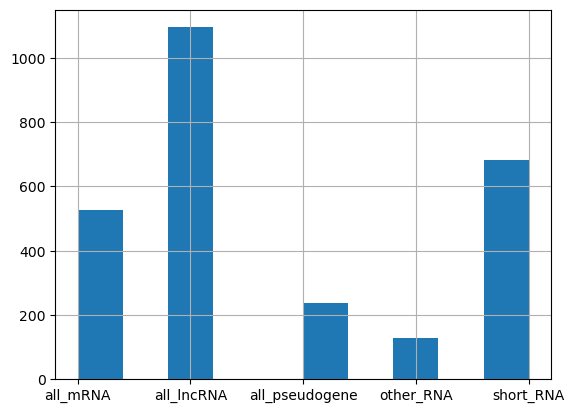

In [218]:
anno_for_bad_genes["geneSuperClass"].hist()

In [230]:
anno_for_bad_lncrna_genes= anno_for_bad_genes[anno_for_bad_genes["geneSuperClass"] == "all_lncRNA"]

In [231]:
anno_for_bad_lncrna_genes["geneSubClass"].value_counts()

geneSubClass
far_from_coding_genes                        420
sense_intron_overlap                         167
divergent_promoters                          145
proximal_to_coding_genes_sense_strand        115
convergent_promoters                         113
ref_within_qry                                61
proximal_to_coding_genes_antisense_strand     40
proximal_to_coding_genes_both_strand          18
tail_to_tail                                  13
head_to_head                                   3
Name: count, dtype: int64

In [232]:
anno_for_bad_lncrna_genes["gene_type"].value_counts()

gene_type
lincRNA                     653
antisense                   276
processed_transcript         61
sense_intronic               36
sense_overlapping            34
misc_RNA                     33
3prime_overlapping_ncrna      2
Name: count, dtype: int64

In [233]:
anno_for_bad_lncrna_genes["geneCategory"].value_counts()

geneCategory
__na                   496
e_lncRNA               323
p_lncRNA_divergent     152
p_lncRNA_intergenic    124
Name: count, dtype: int64

In [214]:
anno_for_bad_genes.loc[667043, 8]

'gene_id "ENSG00000031544.10"; geneSuperClass "all_lncRNA";  geneClass "lncRNA_intergenic";  geneSubClass "far_from_coding_genes"; gene_type "processed_transcript"; gene_name "NR2E3"; coding_status "uncertain"; cumulative_support "ENCODE:FANTOM:GENCODE:HUBDMAP:MITRANS"; geneCategory "e_lncRNA"; DHS_type "DHS_enhancer";'

### Сравнение коррдинат и  длины гена ADAR в разных сборках

In [157]:
fantom_hg19[fantom_hg19["unique_genome_reg_name"] == "ENSG00000160710-gene"]

,0,3,4,unique_genome_reg_name
3399181,chr1,154546952,154600444,ENSG00000160710-gene


In [158]:
154600444 - 154546952

53492

In [149]:
fantom_ensgenes_hg38[fantom_ensgenes_hg38["name"] == "ENSG00000160710-gene"]

,chrom,start,end,name
303763,chr1,154574476,154627968,ENSG00000160710-gene


In [159]:
154627968 - 154574476

53492

In [150]:
ensembl_genes_hg38[ensembl_genes_hg38["name"] == "ENSG00000160710-gene"]

,chr,start,end,name
4137,chr1,154581695,154628013,ENSG00000160710-gene


In [160]:
154628013 - 154581695

46318

Конец гена стали совпадать гораздо лучше. Однако, ADAR Находится на "-" цепи, поэтому в данном случае корректнее говорить, что начало генов после переноса fantom на hg38 стало больше походить на разметку ensembl hg38. А вот начало гена (реальный конец) до сих пор довольно сильно не совпадает (7219 bp). Вставет вопрос о корректности выбранного порога на 1кб при аннотации пиков генами

In [161]:
154581695 - 154574476

7219

In [102]:
154627968 - 154628013

-45

## Попытка соотнести гены FANTOM и GENCODE с помощью комбинированного подхода

In [153]:
to_file = GENCODE / 'gencode_genes-hg38-sort.bed'
gencode_genes_sortbed_hg38 = pybedtools.BedTool(to_file)
len(gencode_genes_sortbed_hg38)

78724

In [154]:
to_file = FANTOM / 'fantom_l2_genes-hg38-sort.bed'
fantom_genes_sortbed_hg38 = pybedtools.BedTool(to_file)
len(fantom_genes_sortbed_hg38)

123997

In [147]:
def extract_promoters(genes, upstream=2000, downstream=500):
    """
    Создает BED-файл с промоторами из BED-файла генов.
    
    Parameters:
        genes (str или pybedtools.BedTool): BED-файл с генами.
        upstream (int): Размер области перед TSS (по умолчанию 2000 п.н.).
        downstream (int): Размер области после TSS (по умолчанию 500 п.н.).
    
    Returns:
        pybedtools.BedTool: BED-файл с промоторами.
    """
    
    # Создаем промоторы
    promoters = genes.flank(
        l=2000,
        r=0,
        s=True,                    # Учитывать направленность гена (+/-)
        genome="hg38"              # Указать референсный геном (hg38/mm10 и т.д.), для разрешения краевых случаев
    )
    
    return promoters

In [165]:
gencode_promoters_sortbed_hg38 = extract_promoters(genes=gencode_genes_sortbed_hg38)
len(gencode_promoters_sortbed_hg38)

78724

In [166]:
gencode_promoters_sortbed_hg38.head(3)

chr1	9121	11121	ENSG00000290825-gene	.	+
 chr1	10010	12010	ENSG00000223972-gene	.	+
 chr1	30744	32744	ENSG00000310526-gene	.	-
 

In [157]:
fantom_promoters_sortbed_hg38 = extract_promoters(genes=fantom_genes_sortbed_hg38)
len(fantom_promoters_sortbed_hg38)

123997

In [158]:
fantom_promoters_sortbed_hg38.head(3)

chr1	162485	164485	CATG00000042730-gene	.	-
 chr1	274416	276416	CATG00000042731-gene	.	-
 chr1	634563	636563	CATG00000042732-gene	.	-
 

In [181]:
fantom_promoters_overlap_gencode_hg38 = fantom_promoters_sortbed_hg38.intersect(gencode_promoters_sortbed_hg38, wao=True, s=True)

In [182]:
fantom_promoters_overlap_gencode_hg38 = fantom_promoters_overlap_gencode_hg38.to_dataframe(disable_auto_names=True, header=None)

In [183]:
fantom_promoters_overlap_gencode_hg38

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,chr1,162485,164485,CATG00000042730-gene,.,-,.,-1,-1,.,-1,.,0
1,chr1,274416,276416,CATG00000042731-gene,.,-,.,-1,-1,.,-1,.,0
2,chr1,634563,636563,CATG00000042732-gene,.,-,chr1,633129,635129,ENSG00000293331-gene,.,-,566
3,chr1,629095,631095,ENSG00000223659-gene,.,-,.,-1,-1,.,-1,.,0
4,chr1,627083,629083,ENSG00000248527-gene,.,+,chr1,627062,629062,ENSG00000225972-gene,.,+,1979
...,...,...,...,...,...,...,...,...,...,...,...,...,...
129870,chrY,56850959,56852959,CATG00000115125-gene,.,-,.,-1,-1,.,-1,.,0
129871,chrY,56853491,56855491,CATG00000114976-gene,.,+,chrY,56853244,56855244,ENSG00000235857-gene,.,+,1753
129872,chrY,56856102,56858102,CATG00000115126-gene,.,-,.,-1,-1,.,-1,.,0
129873,chrY,56865675,56867675,CATG00000114977-gene,.,+,.,-1,-1,.,-1,.,0


In [199]:
fantom_promoters_overlap_gencode_hg38[fantom_promoters_overlap_gencode_hg38[12] > 100][3].nunique()

41075

In [187]:
fantom_promoters_overlap_gencode_hg38[fantom_promoters_overlap_gencode_hg38[3] == "ENSG00000294742-gene"]

,0,1,2,3,4,5,6,7,8,9,10,11,12


In [163]:
199861 - 146386

53475

In [164]:
162485 - 164485

-2000

In [190]:
fantom_genes_hg38[fantom_genes_hg38["name"] == "ENSG00000188399-gene"]

,chrom,start,end,name,score,strand
5178943,chrY,26409169,26625626,ENSG00000188399-gene,.,+


In [193]:
gencode_genes_hg38[gencode_genes_hg38["name"] == "ENSG00000188399-gene"]

,chrom,start,end,name,score,strand
2225173,chrY,26409815,26420535,ENSG00000188399-gene,.,+


In [195]:
26625626 - 26409169

216457

In [196]:
26420535 - 26409815

10720

In [197]:
26409169 - 26409815

-646